<a href="https://colab.research.google.com/github/paulobueno90/AirBnB-Udacity-Project/blob/master/6_1_ObvBasedStrategy_Research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Trend Following OBV-Based Strategy ( Part - II )**

## **Intro**

---

This notebook is a continuation of the initial research with OBV-Based strategy, so initial thoughts remain the same as in the first notebook: [6-ObvBasedStrategy-Research](https://github.com/GBR-Research/Research-Notebooks/blob/main/6-ObvBasedStrategy-Research.ipynb)

In this notebook it will be presented small changes from the last model of the first notebook and it will present the new ETH model, how it was made and how it can be used with other alt coins using betas.

## **Modifications**

---

At the core of the strategy, some modifications were made, from the beginning , on both timeframes,  moving averages were used for the price and for the OBV, but it was noticed that the model did not benefit much from using moving averages and risk bands on the larger timeframe (4H). Therefore, moving averages relative to price on the higher timeframe has been removed.

The original idea was to use something balanced between price and volume, but in exhaustive tests, it became clear that the volume used in the form of OBV was more important than the price. So it is already clear that the price is just a form of confirmation to avoid noise or prevent entries where the price is too far away so that the risk is disproportionate to the opportunity.

## **ADDED Features**

---

The first optimizations were able to improve models performance, but in the initial concept we optimized the strategy for short-side in order to avoid 'long-bias' ( Almost all assets going up in the past 10 years ).


### **1 - Merged Models**

---

**Problem:**

- Although the models were able to remain stable, it was clear that the model couldn't get the most of the bull market.

**Solution:**

- Optimize for LONG and SHORT separately.
- Merge the best long and the best short model.
- Make it neutral in case the two models conflicts (both send 'open position')


### **2 - Signal Transfer**

---

Creating strategies for Bitcoin or Ethereum volume-based seems to work in a stable manner, but for other coins ( alt-coins ) this is not exactly true. The main reason is probably that it is difficult to measure how much we can trust the model developed for them since a lot of them are recent and don't have enough data ( at least 2-3 years ) for good optimization. Overfitting altcoins can be very dangerous since their behavior can change anytime.

The solution to this problem could be to use Bitcoin and Ethereum models (which are stable) and transfer their signals to altcoins.

Although using this signals blindly (ETH->SOL) can generate good signals, it completely ignores the current state of the target coin since it is trading one asset with other signal (cross-asset strategy).

#### **2.1 - Betas as Filters**

Thinking about this problem of ignoring the current state of the target asset, it was thought to use the covariance ( BETA ) between the percentage returns of the target asset, the main asset of the model, and Bitcoin (if the asset of the base model is not BTC).

This idea it is a link between the OBV model and the previous research steps:
- [2-Beta_Research.ipynb](https://github.com/GBR-Research/Research-Notebooks/blob/main/2-Beta_Research.ipynb)
- [3-VolumeBeta_Strategy.ipynb](https://github.com/GBR-Research/Research-Notebooks/blob/main/3-VolumeBeta_Strategy.ipynb)

The calculations are the same as in the previous research, except that we are not using Daily Abnormal volume.

**What is the idea behind it ?**

In the abnormal volume and beta signals, we have that when the beta (coin X BTC) between an altcoin is lower than 1 and higher than -1, if Bitcoin is going down, this could mean that this coin has lost correlation with the benchmark (BTC), which could mean that it could rise in the next few days as the coin has resisted the drag of the main coin going down.

So, there are different combinations that can benefit this line of thought like:

- (ETH X BTC) Beta < 1.4

If this coin will follow Ethereum signal and Ethereum itself is uncorrelated to BTC at that time, it could mean that ETH is in a idiosyncratic movement in relation to the overall market (assuming that BTC is the benchmark and it has the capability of dragging all other coins).

This notebook couldn't explore all possibilities of this model, but in theory it is possible to create very complex models using some sort of hedge using non-USD pairs like COIN-BTC or COIN-ETH.

 # **Notebook - INDEX** <a name="Part0"></a>

* [1 - Importing Libraries](#Part1) 

* [2 - FUNCTIONS & CLASSES](#Part2) 

* [3 - Best Models Selected](#Part3)

* [4 - Download Data](#Part4)

* [5 - Merged Models](#Part5)

* [6 - Signal Transfer](#Part6)

* [7 - Comments and Suggestions](#Part7)

 <h2><center><strong>Import Libraries</strong></center></h2> <a name="Part1"></a>

# **1 - Importing Libraries**

 <h1><center><strong>Import Libraries</strong></center></h1> <a name="Part1"></a>

In order to use the functions of this notebook it will be necessary to install 'backtrader' lib, at least to get equity curve, return X intratrade-drawndown and etc.

In [1]:
!pip install backtrader

     |████████████████████████████████| 410 kB 5.3 MB/s 


In [2]:
import os

import urllib.request
from dateutil.relativedelta import relativedelta

import datetime as dt
from datetime import datetime

import math
import numpy as np
import pandas as pd

import backtrader as bt

import matplotlib.pyplot as plt
import seaborn as sns

import altair as alt
alt.data_transformers.disable_max_rows()

DataTransformerRegistry.enable('default')

**Notebook Configs**

In [3]:
import warnings
warnings.filterwarnings('ignore')

# Setting Seaborn Theme
sns.set_theme(style="whitegrid", font_scale=1.4)

plt.rcParams["figure.figsize"] = (18,10)

# **2 - FUNCTIONS & CLASSES**

---

 <h1><center><strong>2 - FUNCTIONS & CLASSES</strong></center></h1> <a name="Part2"></a>

  <center>
 
 [Go back to INDEX](#Part0)
 
 </center>

 
 ---

##2.1 - Binance Data Functions

In [4]:
#=======================================================================================================#
#  BINANCE DATA FUNCTIONS
#=======================================================================================================#


def remove_temp_files(files_list):
    """
    Delete csv files downloaded
    :param files_list: list(str), path to csv files downloaded to update the database
    :return: None
    """
    for file_name in files_list:

        if os.path.exists(file_name):
            os.remove(file_name)

        else:
            print("The file does not exist")


def download_url(url, save_path):
    with urllib.request.urlopen(url) as dl_file:
        with open(save_path, 'wb') as out_file:
            out_file.write(dl_file.read())


def download_btc_data(coin='BTC'):
    if coin not in os.listdir():
        os.mkdir(coin)
    else:
        datasets_files = os.listdir(coin)
        if len(datasets_files) > 0:
            datasets_files = [f'{coin}/{f}' for f in datasets_files]
            remove_temp_files(datasets_files)

    symbol = coin
    end_date = datetime.now()
    target_date = end_date.date() - dt.timedelta(days=1)

    first_date_str = "2018-01"
    first_date = datetime.strptime(first_date_str, "%Y-%m")
    download_date = first_date

    target_date = datetime.now() - dt.timedelta(days=1)

    target_month = datetime.strptime(target_date.strftime('%Y-%m'), "%Y-%m")

    url = f"https://data.binance.vision/data/spot/monthly/klines/{coin}USDT/1m/"
    path = f"./{coin}/"
    files_list = []

    while download_date < target_month:
        file = f"{coin}USDT-1m-{download_date.strftime('%Y-%m')}.zip"
        download_url(url + file, path + file)
        btc_df = pd.read_csv(path + file, names=['Open time',
                                                 'Open',
                                                 'High',
                                                 'Low',
                                                 'Close',
                                                 'Volume',
                                                 'Close time',
                                                 'Quote asset volume',
                                                 'Number of trades',
                                                 'Taker buy base asset volume',
                                                 'Taker buy quote asset volume',
                                                 'Ignore'])

        btc_df.sort_index(inplace=True)
        btc_df['datetime'] = btc_df['Open time'].apply(lambda x: datetime.utcfromtimestamp(int(x / 1000)))
        btc_df.set_index('datetime', drop=True, inplace=True)
        btc_df.drop('Open time', inplace=True, axis=1)
        # btc_df.to_sql('BTC', con=cnx, if_exists='append')
        btc_df.to_csv(f'{coin}.csv', mode='a', header=False)

        download_date = download_date + relativedelta(months=1)
        files_list.append(path + file)
        print(f"{symbol} | {path + file} ok!")

    url = f"https://data.binance.vision/data/spot/daily/klines/{coin}USDT/1m/"
    download_date = target_month

    while download_date < target_date:
        file = f"{coin}USDT-1m-{download_date.strftime('%Y-%m-%d')}.zip"
        download_url(url + file, path + file)
        btc_df = pd.read_csv(path + file, names=['Open time',
                                                 'Open',
                                                 'High',
                                                 'Low',
                                                 'Close',
                                                 'Volume',
                                                 'Close time',
                                                 'Quote asset volume',
                                                 'Number of trades',
                                                 'Taker buy base asset volume',
                                                 'Taker buy quote asset volume',
                                                 'Ignore'])

        btc_df.sort_index(inplace=True)
        btc_df['datetime'] = btc_df['Open time'].apply(lambda x: datetime.utcfromtimestamp(int(x / 1000)))
        btc_df.set_index('datetime', drop=True, inplace=True)
        btc_df.drop('Open time', inplace=True, axis=1)
        # btc_df.to_sql('BTC', con=cnx, if_exists='append')
        btc_df.to_csv(f'{coin}.csv', mode='a', header=False)

        download_date = download_date + dt.timedelta(days=1)
        files_list.append(path + file)
        print(f"{symbol} | {path + file} ok!")


def get_data(coin='BTC', volume=False):
    df = pd.read_csv(f'{coin}.csv', names=['datetime',
                                           'open',
                                           'high',
                                           'low',
                                           'close',
                                           'volume',
                                           'close time',
                                           'Quote asset volume',
                                           'Number of trades',
                                           'Taker buy base asset volume',
                                           'Taker buy quote asset volume',
                                           'Ignore'])

    df['datetime'] = pd.to_datetime(df['datetime'])
    df.set_index('datetime', inplace=True, drop=True)

    df.drop(['close time',
             'Number of trades',
             'Taker buy base asset volume',
             'Taker buy quote asset volume',
             'Ignore'],

            axis=1,
            inplace=True
            )
    df.rename(columns={'Quote asset volume': 'financial_volume'}, inplace=True)

    if not volume:
        df['volume'] = df['financial_volume']

    df = df.resample('5min').agg({'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume': 'sum'})

    return df


def get_data_1m(coin='BTC', volume=False):
    df = pd.read_csv(f'{coin}.csv', names=['datetime',
                                           'open',
                                           'high',
                                           'low',
                                           'close',
                                           'volume',
                                           'close time',
                                           'Quote asset volume',
                                           'Number of trades',
                                           'Taker buy base asset volume',
                                           'Taker buy quote asset volume',
                                           'Ignore'])

    df['datetime'] = pd.to_datetime(df['datetime'])
    df.set_index('datetime', inplace=True, drop=True)

    df.drop(['close time',
             'Number of trades',
             'Taker buy base asset volume',
             'Taker buy quote asset volume',
             'Ignore'],

            axis=1,
            inplace=True
            )
    df.rename(columns={'Quote asset volume': 'financial_volume'}, inplace=True)

    if not volume:
        df['volume'] = df['financial_volume']

    df = df.resample('1min').agg({'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume': 'sum'})

    return df


def resample_dataset(timeframe, data):
    """Transform data to other timeframe"""
    return data.resample(timeframe).agg(
        {'open': 'first', 'high': 'max', 'low': 'min', 'close': 'last', 'volume': 'sum'})


def download_alt_data(coin='BTC'):
    if coin not in os.listdir():
        os.mkdir(coin)
    else:
        datasets_files = os.listdir(coin)
        if len(datasets_files) > 0:
            datasets_files = [f'{coin}/{f}' for f in datasets_files]
            remove_temp_files(datasets_files)

    symbol = coin
    end_date = datetime.now()
    target_date = end_date.date() - dt.timedelta(days=1)

    first_date_str = "2021-03"
    first_date = datetime.strptime(first_date_str, "%Y-%m")
    download_date = first_date

    target_date = datetime.now() - dt.timedelta(days=1)

    target_month = datetime.strptime(target_date.strftime('%Y-%m'), "%Y-%m")

    path = f"./{coin}/"
    files_list = []

    url = f"https://data.binance.vision/data/spot/daily/klines/{coin}USDT/1m/"

    while download_date < target_date:
        file = f"{coin}USDT-1m-{download_date.strftime('%Y-%m-%d')}.zip"
        download_url(url + file, path + file)
        btc_df = pd.read_csv(path + file, names=['Open time',
                                                 'Open',
                                                 'High',
                                                 'Low',
                                                 'Close',
                                                 'Volume',
                                                 'Close time',
                                                 'Quote asset volume',
                                                 'Number of trades',
                                                 'Taker buy base asset volume',
                                                 'Taker buy quote asset volume',
                                                 'Ignore'])

        btc_df.sort_index(inplace=True)
        btc_df['datetime'] = btc_df['Open time'].apply(lambda x: datetime.utcfromtimestamp(int(x / 1000)))
        btc_df.set_index('datetime', drop=True, inplace=True)
        btc_df.drop('Open time', inplace=True, axis=1)
        # btc_df.to_sql('BTC', con=cnx, if_exists='append')
        btc_df.to_csv(f'{coin}.csv', mode='a', header=False)

        download_date = download_date + dt.timedelta(days=1)
        files_list.append(path + file)
        print(f"{symbol} | {path + file} ok!")


def download_alt_data_by_ticker(coin='BTC', fd="2021-03"):
    if coin not in os.listdir():
        os.mkdir(coin)
    else:
        datasets_files = os.listdir(coin)
        if len(datasets_files) > 0:
            datasets_files = [f'{coin}/{f}' for f in datasets_files]
            remove_temp_files(datasets_files)

    symbol = coin
    end_date = datetime.now()
    target_date = end_date.date() - dt.timedelta(days=1)

    first_date_str = fd
    first_date = datetime.strptime(first_date_str, "%Y-%m")
    download_date = first_date

    target_date = datetime.now() - dt.timedelta(days=1)

    target_month = datetime.strptime(target_date.strftime('%Y-%m'), "%Y-%m")

    path = f"./{coin}/"
    files_list = []

    url = f"https://data.binance.vision/data/spot/daily/klines/{coin}/1m/"

    while download_date < target_date:
        file = f"{coin}-1m-{download_date.strftime('%Y-%m-%d')}.zip"
        download_url(url + file, path + file)
        btc_df = pd.read_csv(path + file, names=['Open time',
                                                 'Open',
                                                 'High',
                                                 'Low',
                                                 'Close',
                                                 'Volume',
                                                 'Close time',
                                                 'Quote asset volume',
                                                 'Number of trades',
                                                 'Taker buy base asset volume',
                                                 'Taker buy quote asset volume',
                                                 'Ignore'])

        btc_df.sort_index(inplace=True)
        btc_df['datetime'] = btc_df['Open time'].apply(lambda x: datetime.utcfromtimestamp(int(x / 1000)))
        btc_df.set_index('datetime', drop=True, inplace=True)
        btc_df.drop('Open time', inplace=True, axis=1)
        # btc_df.to_sql('BTC', con=cnx, if_exists='append')
        btc_df.to_csv(f'{coin}.csv', mode='a', header=False)

        download_date = download_date + dt.timedelta(days=1)
        files_list.append(path + file)
        print(f"{symbol} | {path + file} ok!")

##2.2 - Backtrader-Related Functions

**Beta Functions**

In [5]:
def calculate_beta(stock, market):
    return np.cov(stock, market)[0][1] / np.var(market)


def get_betas(df, n):
    data = df.to_numpy()
    a = []
    b = []
    for i in range(n):
        a.append(np.nan)
        b.append(np.nan)

    for i in range(len(df) - n):
        a.append(data[i:i + n, 0])
        b.append(data[i:i + n, 1])

    betas = []
    for i, j in zip(a, b):
        betas.append(calculate_beta(i, j))

    return betas

**Signal Class**

In [34]:
class ObvModels():
    def __init__(self, model_coin, long_params, short_params, target_coin, btc_m_beta= False,btc_m_beta_side=False, btc_t_beta=False,btc_t_beta_side=False, m_t_beta=False, m_t_beta_side=False, trade_side=0,beta_n=72):
        self.id_ticker = model_coin
        # Strategy Parameters
        self.p_long = long_params
        self.p_short = short_params
        self.target_coin = target_coin
        self.btc_m_beta = btc_m_beta
        self.btc_t_beta = btc_t_beta
        self.m_t_beta = m_t_beta
        self.btc_m_beta_side = btc_m_beta_side
        self.btc_t_beta_side = btc_t_beta_side
        self.m_t_beta_side = m_t_beta_side
        self.trade_side = trade_side
        self.beta_n = 72
        

    def getdata(self):
        df = get_data(coin=self.id_ticker, volume=True)
        df = df.resample('5min').agg({'open':'first','high':'max','low':'min','close':'last','volume':'sum'})
        df_1h = df.resample('1H').agg({'open':'first','high':'max','low':'min','close':'last','volume':'sum'})

        if self.target_coin == self.id_ticker:
            target_data = df_1h.copy()
        else:
            target_data = get_data(coin=self.target_coin, volume=True)
            target_data = target_data.resample('1H').agg({'open':'first','high':'max','low':'min','close':'last','volume':'sum'})

        df_4h = df_1h.copy()
        df_4h = df_4h.resample('4H').agg({'open':'first','high':'max','low':'min','close':'last','volume':'sum'})

        return df_1h, df_4h, target_data

    def run(self):
        # get dataframes
        df1, df4, target_data = self.getdata()

        # Calculate indicators
        res = self.calc(df1, df4, self.p)
        rev_res = res.iloc[::-1]
        with open('signals.htm', 'w') as fl:
            fl.truncate()
            fl.write(rev_res[['coin', 'long_o', 'short_o', 'long_c', 'short_c', 'signal']].to_html())

        return res
        # Saveg signal
        # cls.save()

    def run_html(self, filename=None):

        # get dataframes
        df1, df4, target_data = self.getdata()

        # Calculate indicators
        data_long = self.calc(df1, df4, self.p_long)
        data_short = self.calc(df1, df4, self.p_short)

        # Get Signals
        signals = self.ensemble_models(
            signals_long  = data_long, 
            signals_short = data_short,
            df1           = target_data,
            )

        # Betas
        signals = self.beta_check(target_data, df1, signals, n=self.beta_n)

        # Create Plot
        chart = self.generate_plot(signals)
        
        # Save HTML
        if filename == None:
            chart.save(f'./signals.html', embed_options={'renderer': 'svg'})
        else:
            chart.save(f'./{filename}.html', embed_options={'renderer': 'svg'})

    def calculate_beta(self,stock, market):
        return np.cov(stock, market)[0][1] / np.var(market)


    def get_betas(self,df, n):
        data = df.to_numpy()
        a = []
        b = []
        for i in range(n):
            a.append(np.nan)
            b.append(np.nan)

        for i in range(len(df) - n):
            a.append(data[i:i + n, 0])
            b.append(data[i:i + n, 1])

        betas = []
        for i, j in zip(a, b):
            betas.append(self.calculate_beta(i, j))

        return betas

    def beta_check(self, coin_data, model_coin_data, signals, n=72):

        if (self.btc_m_beta != False) or (self.btc_t_beta != False):
            btc_data = get_data(coin='BTC', volume=True).resample('1H').agg({'open':'first','high':'max','low':'min','close':'last','volume':'sum'})


            if self.btc_m_beta:

                close_data = pd.concat([model_coin_data[['close']].rename(columns={'close':'c1'}), btc_data[['close']].rename(columns={'close':'c2'})], axis=1)
                close_data.columns = [0,1]
                close_data = close_data.pct_change() * 100
                close_data[f'beta_{self.id_ticker}_BTC'] = self.get_betas(close_data, n)
                signals = pd.concat([signals,close_data[[f'beta_{self.id_ticker}_BTC']]],axis=1)
                

                if self.btc_m_beta_side==1:
                    signals[f'beta_{self.id_ticker}_BTC'] = (signals[f'beta_{self.id_ticker}_BTC'] > self.btc_m_beta) * 1
                
                elif self.btc_m_beta_side==-1:
                    signals[f'beta_{self.id_ticker}_BTC'] = (signals[f'beta_{self.id_ticker}_BTC'] < self.btc_m_beta) * 1
                
                signals['long_o'] = signals[f'beta_{self.id_ticker}_BTC'] * signals['long_o']
                signals['short_o'] = signals[f'beta_{self.id_ticker}_BTC'] * signals['short_o']

                signals['long_c'] = ((signals[f'beta_{self.id_ticker}_BTC']==0) | (signals['long_c']==1)) * 1
                signals['short_c'] = ((signals[f'beta_{self.id_ticker}_BTC']==0) | (signals['short_c']==1)) * 1

                signals.drop([f'beta_{self.id_ticker}_BTC'],axis=1,inplace=True)
                

            if self.btc_t_beta:

                close_data = pd.concat([coin_data[['close']].rename(columns={'close':'c1'}), btc_data[['close']].rename(columns={'close':'c2'})], axis=1)
                close_data.columns = [0,1]
                close_data = close_data.pct_change() * 100
                close_data[f'beta_{self.target_coin}_BTC'] = self.get_betas(close_data, n)
                signals = pd.concat([signals,close_data[[f'beta_{self.target_coin}_BTC']]],axis=1)

                if self.btc_t_beta_side==1:
                    signals[f'beta_{self.target_coin}_BTC'] = (signals[f'beta_{self.target_coin}_BTC'] > self.btc_t_beta) * 1
                
                elif self.btc_t_beta_side==-1:
                    signals[f'beta_{self.target_coin}_BTC'] = (signals[f'beta_{self.target_coin}_BTC'] < self.btc_t_beta) * 1
                
                signals['long_o'] = signals[f'beta_{self.target_coin}_BTC'] * signals['long_o']
                signals['short_o'] = signals[f'beta_{self.target_coin}_BTC'] * signals['short_o']

                signals['long_c'] = ((signals[f'beta_{self.target_coin}_BTC']==0) | (signals['long_c']==1)) * 1
                signals['short_c'] = ((signals[f'beta_{self.target_coin}_BTC']==0) | (signals['short_c']==1)) * 1

                signals.drop([f'beta_{self.target_coin}_BTC'],axis=1,inplace=True)

        if self.m_t_beta != False:

            close_data = pd.concat([coin_data[['close']].rename(columns={'close':'c1'}), model_coin_data[['close']].rename(columns={'close':'c2'})], axis=1)
            close_data.columns = [0,1]
            close_data = close_data.pct_change() * 100
            close_data[f'beta_{self.target_coin}_{self.id_ticker}'] = self.get_betas(close_data, n)
            signals = pd.concat([signals,close_data[[f'beta_{self.target_coin}_{self.id_ticker}']]],axis=1)

            if self.m_t_beta_side==1:
                signals[f'beta_{self.target_coin}_{self.id_ticker}'] = (signals[f'beta_{self.target_coin}_{self.id_ticker}'] > self.m_t_beta) * 1
            
            elif self.m_t_beta_side==-1:
                signals[f'beta_{self.target_coin}_{self.id_ticker}'] = (signals[f'beta_{self.target_coin}_{self.id_ticker}'] < self.m_t_beta) * 1
            
            signals['long_o'] = signals[f'beta_{self.target_coin}_{self.id_ticker}'] * signals['long_o']
            signals['short_o'] = signals[f'beta_{self.target_coin}_{self.id_ticker}'] * signals['short_o']

            signals['long_c'] = ((signals[f'beta_{self.target_coin}_{self.id_ticker}']==0) | (signals['long_c']==1)) * 1
            signals['short_c'] = ((signals[f'beta_{self.target_coin}_{self.id_ticker}']==0) | (signals['short_c']==1)) * 1

            signals.drop([f'beta_{self.target_coin}_{self.id_ticker}'],axis=1,inplace=True)

        return signals



    def backtest_run(self):

        # get dataframes
        df1, df4, target_data = self.getdata()

        # Calculate indicators
        data_long = self.calc(df1, df4, self.p_long)
        data_short = self.calc(df1, df4, self.p_short)

        # Get Signals
        signals = pd.concat([
                             data_long[['long_o','long_c']], 
                             data_short[['short_o','short_c']]
                             ],
                            axis=1)
        
        signals.ffill(inplace=True)

        signals = pd.concat([target_data[['open','high','low','close','volume']], signals], axis=1)
        signals = self.beta_check(target_data, df1, signals, n=self.beta_n)
        signals = signals.loc[target_data[['close']].dropna().index]

        signals.index = pd.to_datetime(signals.index, unit='ms')

        if   self.trade_side == 1:
            signals['short_o'] = 0
        elif self.trade_side == -1:
            signals['long_o'] = 0

        
        # BACKTRADER BACKTEST
        data = ObvStratData(dataname=signals,
                        datetime=None,
                        open='open',
                        high='high',
                        low='low',
                        close='close',
                        volume='volume',
                        long_o='long_o',
                        short_o='short_o',
                        long_c='long_c',
                        short_c='short_c',
                        timeframe=bt.TimeFrame.Minutes,
                        compression=60
                        )
    
        cerebro, output = run_backtest(data, use_p=False)

        # EQUITY CURVE
        equity = output[0].analyzers.cashmarket.get_analysis()

        equity = pd.DataFrame(equity).transpose()
        equity.columns = ['Cash', 'Equity']
        equity = equity[['Equity']]

        # Create an object for plotting
        self.equity_curve = equity
        self.df1h_data = df1
        self.target_data = target_data

        # GET TRADES
        transactions = output[0].analyzers.transactions.get_analysis()

        all_transactions = []
        for d, tc in transactions.items():
            #print(d,tc)
            tc_temp = tc[0]
            transaction = {}
            transaction['datetime'] = d
            transaction['size'] = tc_temp[0]
            transaction['price'] = tc_temp[1]
            transaction['amount'] = tc_temp[4]

            all_transactions.append(transaction)

        all_transactions = pd.DataFrame(all_transactions)

        matched_transactions = []
        trade = {}
        for i in range(0,all_transactions.shape[0],2):
            trade = {}
            datapoint = all_transactions.loc[i]
            
            
            trade['open_date'] = datapoint['datetime']
            trade['open_size'] = datapoint['size']
            trade['open_price'] = datapoint['price']
            trade['open_amount'] = datapoint['amount']
            try:

                datapoint1 = all_transactions.loc[i+1]

                trade['close_date'] = datapoint1['datetime']
                trade['close_size'] = datapoint1['size']
                trade['close_price'] = datapoint1['price']
                trade['close_amount'] = datapoint1['amount']

                matched_transactions.append(trade)

            except:

                trade['close_date'] = np.nan
                trade['close_size'] = np.nan
                trade['close_price'] = np.nan
                trade['close_amount'] = np.nan

                matched_transactions.append(trade)

        trades = pd.DataFrame(matched_transactions)
        trades['output'] = trades['close_amount'] + trades['open_amount']


        trades['pnl'] = trades['output'].cumsum()

        trades['return'] =  ((trades['close_amount'] + trades['open_amount']) / np.abs(trades['open_size'])) / trades['open_price']
        trades['side'] = (trades['open_size'] > 0) * 1
        trades['side'] = trades['side'].replace([0],-1)

        trades['L'] = np.nan
        trades['H'] = np.nan
        trades['MPE'] = np.nan
        trades['MNE'] = np.nan

        for i, row in trades.iterrows():
            temp_data = target_data.loc[row['open_date']: row['close_date'] - dt.timedelta(hours=1)].copy()
            
            trades.loc[trades.index == i,'L'] = temp_data['low'].min()
            trades.loc[trades.index == i,'H'] = temp_data['high'].max()

            if row['side'] == 1:
                trades.loc[trades.index == i,'MPE'] = (trades.loc[trades.index == i]['H'] - row['open_price']) / row['open_price']
                trades.loc[trades.index == i,'MNE'] = (trades.loc[trades.index == i]['L'] - row['open_price']) / row['open_price']

            elif row['side'] == -1:
                trades.loc[trades.index == i,'MPE'] = ((trades.loc[trades.index == i]['L'] - row['open_price']) / row['open_price']) * (-1)
                trades.loc[trades.index == i,'MNE'] = ((trades.loc[trades.index == i]['H'] - row['open_price']) / row['open_price']) * (-1)


        trades['r'] = trades['return'].copy()
        trades['Cumulative Returns'] = trades['return'] + 1
        trades['dayofweek'] = trades['open_date'].apply(lambda x: x.strftime("%w - %A"))
        trades['hour'] = trades['open_date'].apply(lambda x: x.hour)
        trades['dayofmonth'] = trades['open_date'].apply(lambda x: x.day)
        trades['month'] = trades['open_date'].apply(lambda x: x.month)

        self.trades = trades


    def plot_equity(self, plot=0, start_date=None, end_date=None):

        if plot==0:
            equity = pd.concat([self.df1h_data[['close']], self.equity_curve], axis=1)
        elif plot==1:
            equity = pd.concat([self.target_data[['close']], self.equity_curve], axis=1)
        
        first_index = self.target_data.index[0].strftime('%Y-%m-%d %H:%M') if start_date == None else start_date
        last_index = (equity.index[-1] + dt.timedelta(hours=1)).strftime('%Y-%m-%d %H:%M') if end_date == None else end_date
        equity = equity.loc[first_index : last_index]
        equity = equity.pct_change() + 1
        equity = equity.fillna(1)
        equity = equity.cumprod()
        
        equity.plot()
        plt.show()

    def plot_insights(self):
        # LONG TRADES RETURN VS RISK
        print('_'*200)
        print("LONG TRADES")
        long_trades = self.trades.loc[self.trades['side']==1].copy()

        plt.scatter(long_trades['return'], long_trades['MPE'])
        plt.title('LONG TRADES | RETURN VS Maximum Positive Exposure')
        plt.show()
        print('\n\n')

        plt.scatter(long_trades['return'], long_trades['MNE'])
        plt.title('LONG TRADES | RETURN VS Maximum Negative Exposure')
        plt.show()
        print('\n\n')

        # Number by Day of Week

        long_trades.groupby('dayofweek')[['r']].mean().plot(kind='bar')
        plt.title('LONG TRADES | Mean Return by Day of Week') 
        plt.show()
        print('\n\n')

        long_trades.groupby('dayofweek')[['r']].count().plot(kind='bar')
        plt.title('LONG TRADES | Number of Trades By Day of Week')
        plt.show()
        print('\n\n')

        # By Hour

        long_trades.groupby('hour')[['r']].mean().plot(kind='bar')
        plt.title('LONG TRADES | Mean Return by Hour')
        plt.show()
        print('\n\n')

        long_trades.groupby('hour')[['r']].count().plot(kind='bar')
        plt.title('LONG TRADES | Number of Trades By Hour')
        plt.show()
        print('\n\n')
        

        # SHORT TRADES RETURN VS RISK
        print('_'*200)
        print("SHORT TRADES")
        short_trades = self.trades.loc[self.trades['side']==-1].copy()

        plt.scatter(short_trades['return'], short_trades['MPE'])
        plt.title('SHORT TRADES | RETURN VS Maximum Positive Exposure')
        plt.show()
        print('\n\n')

        plt.scatter(short_trades['return'], short_trades['MNE'])
        plt.title('SHORT TRADES | RETURN VS Maximum Negative Exposure')
        plt.show()
        print('\n\n')

        # Number by Day of Week

        short_trades.groupby('dayofweek')[['r']].mean().plot(kind='bar')
        plt.title('SHORT TRADES | Mean Return by Day of Week') 
        plt.show()
        print('\n\n')

        short_trades.groupby('dayofweek')[['r']].count().plot(kind='bar')
        plt.title('SHORT TRADES | Number of Trades')
        plt.show()
        print('\n\n')

        
        # By Hour


        short_trades.groupby('hour')[['r']].mean().plot(kind='bar')
        plt.title('SHORT TRADES | Mean Return by Hour')
        plt.show()
        print('\n\n')

        short_trades.groupby('hour')[['r']].mean().plot(kind='bar')
        plt.title('SHORT TRADES | Mean Return by Hour')
        plt.show()
        print('\n\n')

        short_trades.groupby('hour')[['r']].count().plot(kind='bar')
        plt.title('SHORT TRADES | Number of Trades By Hour')
        plt.show()

        


    def generate_plot(self, data: pd.DataFrame):

        # ========== #
        # CHART PLOT #
        # ========== #

        data['date'] = data.index.strftime('%Y-%m-%d %H:%M')
        data['YYYY-MM-DD'] = data['date']
        last = data.index[-1] + dt.timedelta(hours=6)
        init = last - dt.timedelta(days=7)

        last = last.strftime('%Y-%m-%d %H:%M')
        init = init.strftime('%Y-%m-%d %H:%M')

        x_init = pd.to_datetime([init, last]).astype(int) / 1E6

        data['signal_buy'] = np.nan
        data.loc[(data['signal'] == 'OPEN LONG') | (data['signal'] == 'CLOSE SHORT'), 'signal_buy'] = \
        data.loc[(data['signal'] == 'OPEN LONG') | (data['signal'] == 'CLOSE SHORT')]['close']

        data['signal_sell'] = np.nan
        data.loc[(data['signal'] == 'OPEN SHORT') | (data['signal'] == 'CLOSE LONG'), 'signal_sell'] = \
        data.loc[(data['signal'] == 'OPEN SHORT') | (data['signal'] == 'CLOSE LONG')]['close']

        position_color = ['darkred', 'forestgreen', 'gray', 'gray', 'gray', 'gray', 'gray', 'gray']
        position_domain = ['SHORT', 'LONG', 'NONE', '', 'OPEN LONG', 'OPEN SHORT', 'CLOSE LONG', 'CLOSE SHORT']
        position_color = alt.Color('signal:N', scale=alt.Scale(domain=position_domain, range=position_color),
                                  legend=None)

        brush = alt.selection_interval(encodings=['x'], init={'x': list(x_init)})

        net_date = alt.Chart().mark_bar().add_selection(
            brush
        ).encode(
            alt.X('date:T'),
            alt.Y('volume:Q'),
            tooltip=['YYYY-MM-DD', 'signal']
        ).properties(width=1000, height=100, data=data)

        base = alt.Chart().encode(
            alt.X('date:T',
                  axis=alt.Axis(
                      format='%m/%d %H:%M',
                      labelAngle=-45,
                      # title='Date in 2009'
                  )
                  )
        )

        rule = base.mark_rule().encode(
            alt.Y(
                'low:Q',
                title='Price',
                scale=alt.Scale(zero=False),
            ),
            alt.Y2('high:Q'),
            color=alt.value('gray')
        )

        bar = base.mark_bar().encode(
            alt.Y('open:Q'),
            alt.Y2('close:Q'),
            tooltip=['YYYY-MM-DD', 'signal'],
            color=position_color
        )

        signal_buy = base.mark_point(shape='triangle', size=100, fill='forestgreen').encode(
            alt.Y('signal_buy'),
            color=alt.value('forestgreen')
        )

        signal_sell = base.mark_point(shape='triangle', size=100, fill='red', angle=180).encode(
            alt.Y('signal_sell'),
            color=alt.value('red'))

        signals_ohlc_chart = (rule + bar + signal_buy + signal_sell).properties(width=1000, height=700,
                                                                                data=data).transform_filter(brush)

        chart = alt.vconcat(net_date,
                            signals_ohlc_chart).properties(data=data)

        # =====================================================
        # Single Line Heatmap ( POSITION )
        # =====================================================

        base_heat = alt.Chart().encode(
            x=alt.X('date:N', title='', axis=None),
            y=alt.Y('coin:N', title=''),
            tooltip=['signal', 'YYYY-MM-DD']
        )

        signals_heatmap = base_heat.mark_rect().encode(
            color=position_color,

        )

        # data_heatmap = data.loc[data.index[-1] - dt.timedelta(hours=72):]
        signals_dashboard = signals_heatmap.properties(width=1000, height=30, data=data, title=alt.TitleParams(
            text=f"Position",
            fontSize=12,
            offset=10)).transform_filter(brush)

        # =====================================================
        # Final Viz
        # =====================================================
        final_plot = alt.vconcat(signals_dashboard, chart,
                                title=alt.TitleParams(text="OBV Signal", fontSize=20,
                                                      subtitle=[
                                                          f"From: {min(data.index).strftime('%Y-%m-%d')} | To: {max(data.index).strftime('%Y-%m-%d')}"],
                                                      subtitleFontSize=12,
                                                      offset=50)).configure_title(anchor='middle')

        return final_plot


    def side(self, x):
        "Function used to create OnBalanceVolume"
        if x > 0:
            return 1
        if x < 0:
            return -1
        return 0

    def indicator_obv(self, data):
        
        data['obv'] = (data['close'].pct_change().apply(self.side)) * (data['volume'])
        # data.dropna(inplace=True)
        data['obv'] = data['obv'].cumsum()

        return None

    def indicator_bands(self, data, column: str, ema_n: int, std_n: int, std_f: float):
        """Creates Exponential Moving Average, upper and lower bands based on standard deviation"""
        data[f'{column}_ema'] = data[f'{column}'].ewm(span=ema_n, adjust=False, min_periods=ema_n).mean()
        data[f'{column}_std'] = data[f'{column}'].rolling(std_n).std(ddof=0)

        data[f'{column}_ema_up'] = data[f'{column}_ema'] + (data[f'{column}_std'] * std_f)
        data[f'{column}_ema_bt'] = data[f'{column}_ema'] - (data[f'{column}_std'] * std_f)

        return None

    def indicator_bands_distance(self, data: pd.DataFrame, upper: float, lower: float, dist_invert: int):
        if dist_invert==1:
            data['upper_distance'] = ((data['high'] / data['close_ema_bt']) < upper) * 1
            data['bottom_distance'] = ((data['low'] / data['close_ema_up']) > lower) * 1
        else:
            data['upper_distance'] = ((data['high'] / data['close_ema_up']) < upper) * 1
            data['bottom_distance'] = ((data['low'] / data['close_ema_bt']) > lower) * 1
        return None

    def signal_1h(self, data: pd.DataFrame, distance: int):
        
        # Open Position Signal
        if distance==1:
            
            data['obv_long_o_1h'] = (data['obv'] > data['obv_ema_up']) * 1
            data['obv_short_o_1h'] = (data['obv'] < data['obv_ema_bt']) * 1
            
            data['signal_long_o_1h'] = data['obv_long_o_1h'] * data['upper_distance']
            data['signal_short_o_1h'] = data['obv_short_o_1h'] * data['bottom_distance']

        elif distance==0:
            data['signal_long_o_1h'] = (data['obv'] > data['obv_ema_up']) * 1
            data['signal_short_o_1h'] = (data['obv'] < data['obv_ema_bt']) * 1

        # Close Position Signal
        data['long_c'] = (data['obv'] < data['obv_ema_up']) * 1
        data['short_c'] = (data['obv'] > data['obv_ema_bt']) * 1
        return None

    def signal_4h(self, data: pd.DataFrame):
        data['signal_long_o_4h'] = (data['obv'] > data['obv_ema_up']) * 1
        data['signal_short_o_4h'] = (data['obv'] < data['obv_ema_bt']) * 1
        return None

    def get_positions(self, data: pd.DataFrame):
        position = []
        first_index = data.index[0]
        for i, row in data.iterrows():

            if i == first_index:

                position.append(0)

            else:

                last_pos = position[-1]

                if last_pos == 0:

                    if (row['long_o'] == 1) and (row['short_o']==0):
                        position.append(1)

                    elif (row['short_o'] == 1) and (row['long_o']==0):
                        position.append(-1)

                    else:
                        position.append(0)

                elif last_pos == 1:

                    if (row['long_c'] == 1) or (row['short_o']==1):
                        position.append(0)

                    else:
                        position.append(last_pos)


                elif last_pos == -1:

                    if (row['short_c'] == 1) or (row['long_o']==1):
                        position.append(0)

                    else:
                        position.append(last_pos)

                else:
                    position.append(0)

        data['position'] = position

        return None

    def get_signals(self, df_1h, df_4h):
        signals = pd.concat([df_1h[['signal_long_o_1h', 'signal_short_o_1h', 'long_c', 'short_c']],
                             df_4h[['signal_long_o_4h', 'signal_short_o_4h']]], axis=1)
        signals.ffill(inplace=True)
        signals.fillna(0, inplace=True)

        signals['long_o'] = signals['signal_long_o_1h'] * signals['signal_long_o_4h']
        signals['short_o'] = signals['signal_short_o_1h'] * signals['signal_short_o_4h']

        return signals

    def calc(self, df1: pd.DataFrame, df4: pd.DataFrame, p: dict):

        df_1h = df1.copy()
        df_4h = df4.copy()

        # Calculate obv
        self.indicator_obv(df_1h)
        self.indicator_obv(df_4h)

        # Indicators
        self.indicator_bands(df_1h,
                             'close',
                             p['close_ema_n_1h'],
                             p['close_std_n_1h'],
                             p['close_std_f_1h'])

        self.indicator_bands(df_1h,
                             'obv',
                             p['obv_ema_n_1h'],
                             p['obv_std_n_1h'],
                             p['obv_std_f_1h'])

        if p['distance'] == 1:
            self.indicator_bands_distance(df_1h,
                                      p['upper_distance'],
                                      p['lower_distance'],
                                      p['dist_invert'])

        # Signals
        self.signal_1h(df_1h, distance=p['distance'])

        # 4 hours Data Processing
        # Indicators
        self.indicator_bands(df_4h,
                             'obv',
                             p['obv_ema_n_4h'],
                             p['obv_std_n_4h'],
                             p['obv_std_f_4h'])

        self.signal_4h(df_4h)

        # Match Time for signals
        df_1h.index = (pd.to_datetime(df_1h.index) + dt.timedelta(hours=1))
        df_4h.index = (pd.to_datetime(df_4h.index) + dt.timedelta(hours=4))

        # Limit 4 hours dataframe index
        last_1h_index = df_1h.index[-1]
        
        df_4h = df_4h.loc[ : last_1h_index]

        # Generate Signals
        signals = self.get_signals(df_1h, df_4h)
        signals.index = signals.index - dt.timedelta(hours=1)  # Fix hour to original
        
        return signals

    def ensemble_models(self, signals_long: pd.DataFrame, signals_short: pd.DataFrame, df1: pd.DataFrame):

        signals = pd.concat([
                             signals_long[['long_o','long_c']], 
                             signals_short[['short_o','short_c']]
                             ],
                            axis=1)
        
        signals.ffill(inplace=True)
        # last 1h Index
        last_1h_index = df1.index[-1]

        # Get Signals as Position
        self.get_positions(signals)

        # Filtering date
        filtered_date = last_1h_index - dt.timedelta(days=120)
        filtered_date = filtered_date.strftime('%Y-%m-%d')
        df = signals.loc[filtered_date:].copy()

        # Set Conditions
        conditions = [(df['position'] == 0) & (df['position'].shift(1) == 0),
                      (df['position'] == 1) & (df['position'].shift(1) == 0),
                      (df['position'] == 1) & (df['position'].shift(1) == 1),
                      (df['position'] == 0) & (df['position'].shift(1) == 1),
                      (df['position'] == -1) & (df['position'].shift(1) == 0),
                      (df['position'] == -1) & (df['position'].shift(1) == -1),
                      (df['position'] == 0) & (df['position'].shift(1) == -1),
                      ]

        values = ['', 'OPEN LONG', 'LONG', 'CLOSE LONG', 'OPEN SHORT', 'SHORT', 'CLOSE SHORT']
        df['signal'] = np.select(conditions, values, default='NONE')
        df['coin'] = self.id_ticker
        df = pd.concat([df1[['open','high','low','close','volume']].loc[filtered_date:], df], axis=1)

        # print(df)
        return df

In [7]:
#==========================================================================================#
# Backtrader Functions/Classes
#==========================================================================================#

# SIZERS

# Custom Pandas Feed for backtrader
lines = ('long_o', 'long_c', 'short_c', 'short_o')
params = (('long_o', -1),
          ('long_c', -1),
          ('short_o', -1),
          ('short_c', -1))

datafields = bt.feeds.PandasData.datafields + (
    ['long_o', 'long_c', 'short_c', 'short_o'])

mydict = dict(
    lines=tuple(lines),
    params=params,
    datafields=bt.feeds.PandasData.datafields + list(lines),
    )

ObvStratData = type('StratData', (bt.feeds.PandasData,), mydict)

class LongOnly(bt.Sizer):
    params = (('stake', 1),)

    def _getsizing(self, comminfo, cash, data, isbuy):

        if np.isfinite(data.close[0]):
            if isbuy:
                divide = math.floor(cash / data.close[0])
                self.p.stake = divide
                return self.p.stake

            # Sell situation
            position = self.broker.getposition(data)
            if not position.size:
                return 0  # do not sell if nothing is open

        return self.p.stake


class ShortOnly(bt.Sizer):
    params = (('stake', 1),)

    def _getsizing(self, comminfo, cash, data, isbuy):

        if not isbuy:
            divide = math.floor(cash / data.close[0])
            self.p.stake = divide
            return self.p.stake

        # Buy situation
        position = self.broker.getposition(data)
        if not position.size:
            return 0  # do not buy if nothing is open

        return self.p.stake


class BothSides(bt.Sizer):
    params = (('stake', 1),)

    def _getsizing(self, comminfo, cash, data, isbuy):

        position = self.broker.getposition(data)

        if isbuy:
            try:
                if position.size < 0:
                    return position.size

                else:
                    divide = math.floor(cash / data.close[0])
                    self.p.stake = divide
                    return self.p.stake
            except:
                return 0

        elif not isbuy:
            try:

                if position.size > 0:
                    return position.size

                else:
                    divide = math.floor(cash / data.close[0])
                    self.p.stake = divide
                    return self.p.stake
                    
            except:
                return 0

        return self.p.stake


# CUSTOM ANALYZER

class CashMarket(bt.analyzers.Analyzer):
    """
    Analyzer returning cash and market values
    """
    def create_analysis(self):
        self.rets = {}
        self.vals = 0.0

    def notify_cashvalue(self, cash, value):
        self.vals = (cash, value)
        self.rets[self.strategy.datetime.datetime()] = self.vals

    def get_analysis(self):
        return self.rets


# "STRATEGY" Class

class ObvTest(bt.Strategy):
    params = dict(close_ema_n_1h=0,
                  close_std_f_1h=0,
                  close_std_n_1h=0,
                  lower_distance=0,
                  obv_ema_n_1h=0,
                  obv_ema_n_4h=0,
                  obv_std_f_1h=0,
                  obv_std_f_4h=0,
                  obv_std_n_1h=0,
                  obv_std_n_4h=0,
                  upper_distance=0,
                  ema=0,
                  distance=0,
                  dist_invert=0,
                  take_profit1=9.9,
                  stop1=-0.9,
                  profit_cooldown1=0,
                  loss_cooldown1=0,
                  take_profit2=9.9,
                  stop2=-0.9,
                  profit_cooldown2=0,
                  loss_cooldown2=0,
                  side=None
                  )

    def __init__(self):

        # Get Initial Cash
        self.startcash = self.broker.getvalue()

        # =======================================================#
        # Getting data variables (for readability)               #
        # =======================================================#

        self.data_5m = self.datas[0]

        self.cooldown = 0

    def next(self):

        if self.cooldown == 0:
            if np.isfinite(self.data_5m.close[0]):

                price = self.data_5m.close[0]
                high = self.data_5m.high[0]
                low = self.data_5m.low[0]

                if not self.position:

                    if (self.data_5m.long_o == 1) and (self.data_5m.short_o == 0):
                        self.buy()

                    if (self.data_5m.short_o == 1) and (self.data_5m.long_o == 0):
                        self.sell()


                elif self.position.size > 0:

                    high_diff = ((high - self.position.price) / self.position.price) * (1)
                    low_diff = ((low - self.position.price) / self.position.price) * (1)

                    if high_diff >= self.p.take_profit1:
                        self.close()
                        self.cooldown = int(self.p.profit_cooldown1)

                    elif low_diff <= self.p.stop1:
                        self.close()
                        self.cooldown = int(self.p.loss_cooldown1)

                    elif (self.data_5m.long_c == 1) or (self.data_5m.short_o == 1):
                        self.close()



                elif self.position.size < 0:

                    high_diff = ((high - self.position.price) / self.position.price) * (-1)
                    low_diff = ((low - self.position.price) / self.position.price) * (-1)

                    if low_diff >= self.p.take_profit2:
                        self.close()
                        self.cooldown = int(self.p.profit_cooldown2)

                    elif high_diff <= self.p.stop2:
                        self.close()
                        self.cooldown = int(self.p.loss_cooldown2)

                    elif (self.data_5m.short_c == 1) or (self.data_5m.long_o == 1):
                        self.close()



        else:
            if self.cooldown > 0:
                self.cooldown -= 1

    def stop(self):
        ls_pnl = self.analyzers.tradeanalyzer.get_analysis()
        short_pnl = ls_pnl.short.pnl.total
        long_pnl = ls_pnl.long.pnl.total
        pnl = round(self.broker.getvalue() - self.startcash, 2)

        print(f"PNL: {pnl} | LONG: {long_pnl} | SHORT: {short_pnl}")


# RUN BACKTEST FUNCTION



def run_backtest(data, params=None, use_p = False):
    """"
    input:

    data: pandas dataframe with the signals already created
    params: dict with parameters used in the strategy, it doesn't affect the output, it was used to get parameters used
    in the optimization or to use risk parameters ( not implemented yet)
    use_p: bool, if true it uses the params variable as parameters in the strategy class.
    """
    # Init Cerebro
    cerebro = bt.Cerebro(maxcpus=1)

    # Initial Ficitional Cash
    startcash = 100000
    cerebro.broker.setcash(startcash)

    # Add Data
    cerebro.adddata(data)

    # Add Sizer
    cerebro.addsizer(BothSides)
    #cerebro.addsizer(LongOnly)

    # Add Analyzer
    cerebro.addanalyzer(bt.analyzers.TradeAnalyzer)
    cerebro.addanalyzer(bt.analyzers.Transactions)
    cerebro.addanalyzer(CashMarket)



    # Add Strategy with paramaters as list for optimization
    if use_p:
        cerebro.addstrategy(ObvTest, **params)
    else:
        cerebro.addstrategy(ObvTest)

    # Run
    run_test = cerebro.run() # This will be an output with strategy outcome
    fitness = run_test[0].analyzers.tradeanalyzer.get_analysis().short.pnl.total

    return cerebro, run_test

# **3 - Best Models Selected**

---

 <h1><center><strong>3 - Best Models Selected</strong></center></h1> <a name="Part3"></a>

  <center>
 
 [Go back to INDEX](#Part0)
 
 </center>

 
 ---

Here I created a dictionary of dictionary with the models, which can be used for this notebook, if you want to "play around" with parameters you can create your own dictionary in this format:

```
my_params = {'close_ema_n_1h': 15,
            'close_std_f_1h': 0.5,
            'close_std_n_1h': 40,
            'dist_invert': 1,
            'distance': 1,
            'ema': 0,
            'lower_distance': 0.96,
            'obv_ema_n_1h': 25,
            'obv_ema_n_4h': 45,
            'obv_std_f_1h': 0.5,
            'obv_std_f_4h': 1.0,
            'obv_std_n_1h': 80,
            'obv_std_n_4h': 15,
            'side': 'ALL',
            'upper_distance': 1.04
  }
```

Each key explained:

- ***Price Related***
  - ***close_ema_n_1h***: Close price exponential moving average window size.
  - ***close_std_f_1h***: Close price standard deviation factor that will be used for the "price band" with the exponential moving average.
  - ***close_std_n_1h***: Close price Standard Deviation window ( it is calculated with 'n' periods before the current one)

- ***On Balance Volume Related***
  - ***obv_ema_n_1h***: OBV exponential moving average window size.
  - ***obv_std_f_1h***: OBV standard deviation factor that will be used for the "OBV band" with the exponential moving average.
  - ***obv_std_n_1h***: OBV Standard Deviation window ( it is calculated with 'n' periods before the current one)
  - *Similar names with '4h' instead of '1h' have the same idea behind it but in the 4 hour timeframe.*

- ***Different Config Params***
  - ***ema***: between 0-1, if == 1 it means it will use **price** exponential moving average in the signals. if it is zero, it will not use price bands.
  - ***distance***: betwwen 0-1, add component that consider the price distance from the price bands. Which relates to:
    - ***upper_distance***: Distance threshold to open long position
    - ***lower_distance***: Distance threshold to open short position

  - ***dist_invert***: Between 0-1, if == 1: it invert the bands, considering the lower band to use upper distance.
    - It is indeed a weird thing to do in the model, instead of using the top band distance, using the lower band ( for long ), but this was used not intentionally, but somehow was able to improve the model performance in some cases, which makes the model try to get the movement in the beginning.

  - ***side***: Not related to the model itself, it is to highlight if the model is optimized for long, short or if it is used in both sides. ( Simplify table visualization)

In [8]:
models_params = {
  'BTC MODEL': {'close_ema_n_1h': 15,
  'close_std_f_1h': 0.5,
  'close_std_n_1h': 40,
  'dist_invert': 1,
  'distance': 1,
  'ema': 0,
  'lower_distance': 0.96,
  'obv_ema_n_1h': 25,
  'obv_ema_n_4h': 45,
  'obv_std_f_1h': 0.5,
  'obv_std_f_4h': 1.0,
  'obv_std_n_1h': 80,
  'obv_std_n_4h': 15,
  'side': 'ALL',
  'upper_distance': 1.04},

 'BTC SHORT': {'close_ema_n_1h': 55,
  'close_std_f_1h': 0.5,
  'close_std_n_1h': 60,
  'dist_invert': 1,
  'distance': 1,
  'ema': 1,
  'lower_distance': 0.95,
  'obv_ema_n_1h': 20,
  'obv_ema_n_4h': 30,
  'obv_std_f_1h': 0.2,
  'obv_std_f_4h': 0.1,
  'obv_std_n_1h': 75,
  'obv_std_n_4h': 20,
  'side': 'SHORT',
  'upper_distance': 1.03},
 'ETH LONG': {'close_ema_n_1h': 10,
  'close_std_f_1h': 0.1,
  'close_std_n_1h': 15,
  'dist_invert': 0,
  'distance': 0,
  'ema': 0,
  'lower_distance': 0.92,
  'obv_ema_n_1h': 90,
  'obv_ema_n_4h': 60,
  'obv_std_f_1h': 0.1,
  'obv_std_f_4h': 0.6,
  'obv_std_n_1h': 45,
  'obv_std_n_4h': 15,
  'side': 'LONG',
  'upper_distance': 1.05},

 'ETH MODEL': {'close_ema_n_1h': 50,
  'close_std_f_1h': 0.5,
  'close_std_n_1h': 70,
  'dist_invert': 1,
  'distance': 1,
  'ema': 0,
  'lower_distance': 0.96,
  'obv_ema_n_1h': 25,
  'obv_ema_n_4h': 50,
  'obv_std_f_1h': 0.5,
  'obv_std_f_4h': 0.5,
  'obv_std_n_1h': 35,
  'obv_std_n_4h': 15,
  'side': 'ALL',
  'upper_distance': 1.04},

 'ETH SHORT': {'close_ema_n_1h': 15,
  'close_std_f_1h': 0.9,
  'close_std_n_1h': 80,
  'dist_invert': 1,
  'distance': 1,
  'ema': 0,
  'lower_distance': 0.93,
  'obv_ema_n_1h': 40,
  'obv_ema_n_4h': 50,
  'obv_std_f_1h': 0.2,
  'obv_std_f_4h': 0.5,
  'obv_std_n_1h': 20,
  'obv_std_n_4h': 25,
  'side': 'SHORT',
  'upper_distance': 1.05},

 'ETH SHORT 2': {'close_ema_n_1h': 15,
  'close_std_f_1h': 0.9,
  'close_std_n_1h': 80,
  'dist_invert': 1,
  'distance': 1,
  'ema': 0,
  'lower_distance': 0.93,
  'obv_ema_n_1h': 40,
  'obv_ema_n_4h': 50,
  'obv_std_f_1h': 0.2,
  'obv_std_f_4h': 0.5,
  'obv_std_n_1h': 20,
  'obv_std_n_4h': 25,
  'side': 'SHORT',
  'upper_distance': 1.07},

  'ETH SHORT 3': {
  'close_ema_n_1h': 70,
  'close_std_f_1h': 0.8,
  'close_std_n_1h': 95,
  'dist_invert': 0,
  'distance': 1,
  'ema': 0,
  'lower_distance': 0.99,
  'obv_ema_n_1h': 45,
  'obv_ema_n_4h': 35,
  'obv_std_f_1h': 0.2,
  'obv_std_f_4h': 0.5,
  'obv_std_n_1h': 10,
  'obv_std_n_4h': 10,
  'side': 'SHORT',
  'upper_distance': 1.05
                        }}


models_table = pd.DataFrame(models_params).transpose()
models_table

,close_ema_n_1h,close_std_f_1h,close_std_n_1h,dist_invert,distance,ema,lower_distance,obv_ema_n_1h,obv_ema_n_4h,obv_std_f_1h,obv_std_f_4h,obv_std_n_1h,obv_std_n_4h,side,upper_distance
BTC MODEL,15,0.5,40,1,1,0,0.96,25,45,0.5,1.0,80,15,ALL,1.04
BTC SHORT,55,0.5,60,1,1,1,0.95,20,30,0.2,0.1,75,20,SHORT,1.03
ETH LONG,10,0.1,15,0,0,0,0.92,90,60,0.1,0.6,45,15,LONG,1.05
ETH MODEL,50,0.5,70,1,1,0,0.96,25,50,0.5,0.5,35,15,ALL,1.04
ETH SHORT,15,0.9,80,1,1,0,0.93,40,50,0.2,0.5,20,25,SHORT,1.05
ETH SHORT 2,15,0.9,80,1,1,0,0.93,40,50,0.2,0.5,20,25,SHORT,1.07
ETH SHORT 3,70,0.8,95,0,1,0,0.99,45,35,0.2,0.5,10,10,SHORT,1.05


# **4 - Download Data**

 <h1><center><strong>4 - Download Data</strong></center></h1> <a name="Part4"></a>

  <center>
 
 [Go back to INDEX](#Part0)
 
 </center>

 
 ---

**BTC and ETH Data**

In [9]:
files_now = os.listdir()
if 'BTC.csv' not in files_now:
    download_btc_data()

files_now = os.listdir()
if 'ETH.csv' not in files_now:
    download_btc_data(coin='ETH')

BTC | ./BTC/BTCUSDT-1m-2018-01.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-02.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-03.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-04.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-05.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-06.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-07.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-08.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-09.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-10.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-11.zip ok!
BTC | ./BTC/BTCUSDT-1m-2018-12.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-01.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-02.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-03.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-04.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-05.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-06.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-07.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-08.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-09.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-10.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-11.zip ok!
BTC | ./BTC/BTCUSDT-1m-2019-12.zip ok!
BTC | ./BTC/BTCUSDT-1m-2020-01.zip ok!
BTC | ./BTC/BTCUSDT-1m-20

**Other Coins**

To download other coins try to use this other function like in this Solana example:
```python
download_alt_data(coin='SOL')
```

This function will look for a USDT SPOT coin, which in this case is SOLUSDT, if you want to get other specific ticker with BTC or ETH you can use this other function that takes the exact ticker.

```python
download_alt_data_by_ticker(coin='SOLETH', fd='2021-11')
```

***Note:*** *this 'fd' is for the initial month that it will get data, this is used in the case that the specific ticker have less data available (binance).*

In [18]:
if 'SOL.csv' not in files_now:
    download_alt_data(coin='SOL')

SOL | ./SOL/SOLUSDT-1m-2021-03-01.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-02.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-03.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-04.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-05.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-06.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-07.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-08.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-09.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-10.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-11.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-12.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-13.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-14.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-15.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-16.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-17.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-18.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-19.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-20.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-21.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-22.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-23.zip ok!
SOL | ./SOL/SOLUSDT-1m-2021-03-24.

In [11]:
#if 'SOLETH.csv' not in files_now:
    #download_alt_data_by_ticker(coin='SOLETH', fd='2021-11')

#if 'SOLBTC.csv' not in files_now:
    #download_alt_data_by_ticker(coin='SOLBTC', fd='2021-03')

# **5 - Merged Models**

---

 <h1><center><strong>5 - Merged Models</strong></center></h1> <a name="Part5"></a> 

  <center>
 
 [Go back to INDEX](#Part0)
 
 </center>

 
 ---

## **5.1 - CLASS DEMO - BTC MODEL**

In [12]:
models_table

,close_ema_n_1h,close_std_f_1h,close_std_n_1h,dist_invert,distance,ema,lower_distance,obv_ema_n_1h,obv_ema_n_4h,obv_std_f_1h,obv_std_f_4h,obv_std_n_1h,obv_std_n_4h,side,upper_distance
BTC MODEL,15,0.5,40,1,1,0,0.96,25,45,0.5,1.0,80,15,ALL,1.04
BTC SHORT,55,0.5,60,1,1,1,0.95,20,30,0.2,0.1,75,20,SHORT,1.03
ETH LONG,10,0.1,15,0,0,0,0.92,90,60,0.1,0.6,45,15,LONG,1.05
ETH MODEL,50,0.5,70,1,1,0,0.96,25,50,0.5,0.5,35,15,ALL,1.04
ETH SHORT,15,0.9,80,1,1,0,0.93,40,50,0.2,0.5,20,25,SHORT,1.05
ETH SHORT 2,15,0.9,80,1,1,0,0.93,40,50,0.2,0.5,20,25,SHORT,1.07
ETH SHORT 3,70,0.8,95,0,1,0,0.99,45,35,0.2,0.5,10,10,SHORT,1.05


Before start showing the results of merging diferent models it will be briefly explained how to use the Class for testing/visualize the results.

First take a look in the table in the cell above, which has the best models selected.

This way our models will be using the variable `model_params`, which is a dictionary and the keys are the models in the table above for example if I want to use the parameters of the current Bitcoin Model we pass it as
```python
model_params['BTC MODEL']
```
**Class ObvModels**

- **model_coin:** ticker of the base model
- **long_params:** Parameters used for opening long positions
- **short_params:** Parameters used for opening short positions
- **trade_side:**
  - **0**: backtest with both sides ( long and short)
  - **1**: only long
  - **2**: only short

So that way let's see how the code is used for BTC model for example, since it is a model that uses the same parameters for long and short `long_params` and `short_params`will be equal.

```python
obv_signal = ObvModels(model_coin='BTC', 
                       long_params=models_params['BTC MODEL], 
                       short_params=models_params['BTC MODEL'], 
                       trade_side=0)
                    
```

Let's start the visualization

In [35]:
btc_model = ObvModels(model_coin='BTC', 
                       long_params=models_params['BTC MODEL'], 
                       short_params=models_params['BTC MODEL'],
                       target_coin='BTC',
                       trade_side=0)

**Note:** `target_coin`was passed to the class, but this is mainly for signal transfer that we will see in the section 6

Calculate equity curve

In [36]:
btc_model.backtest_run()

PNL: 3089627.64 | LONG: 2264685.859999998 | SHORT: 824941.7800000025


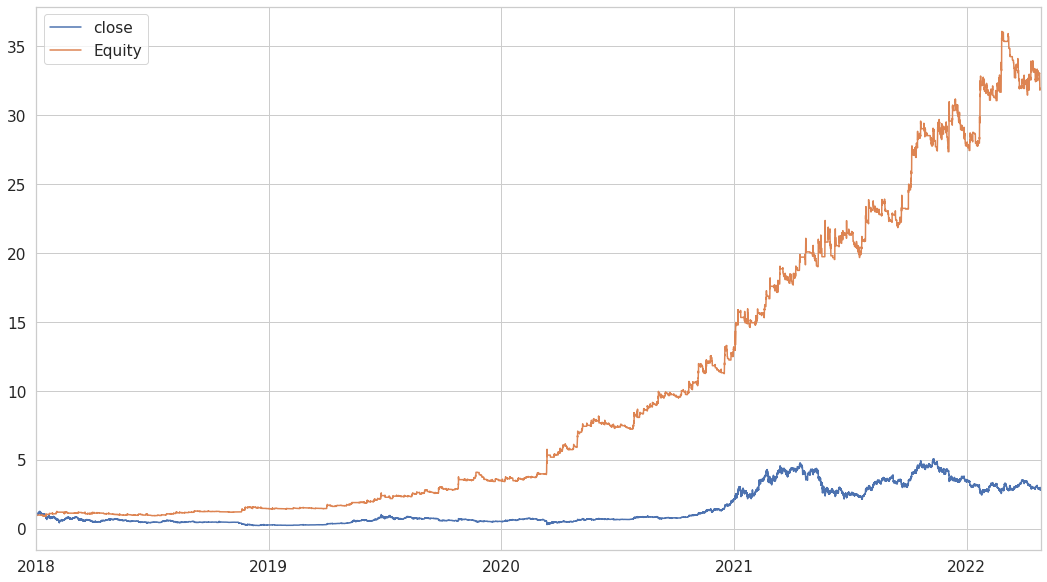

________________________________________________________________________________________________________________________________________________________________________________________________________
LONG TRADES


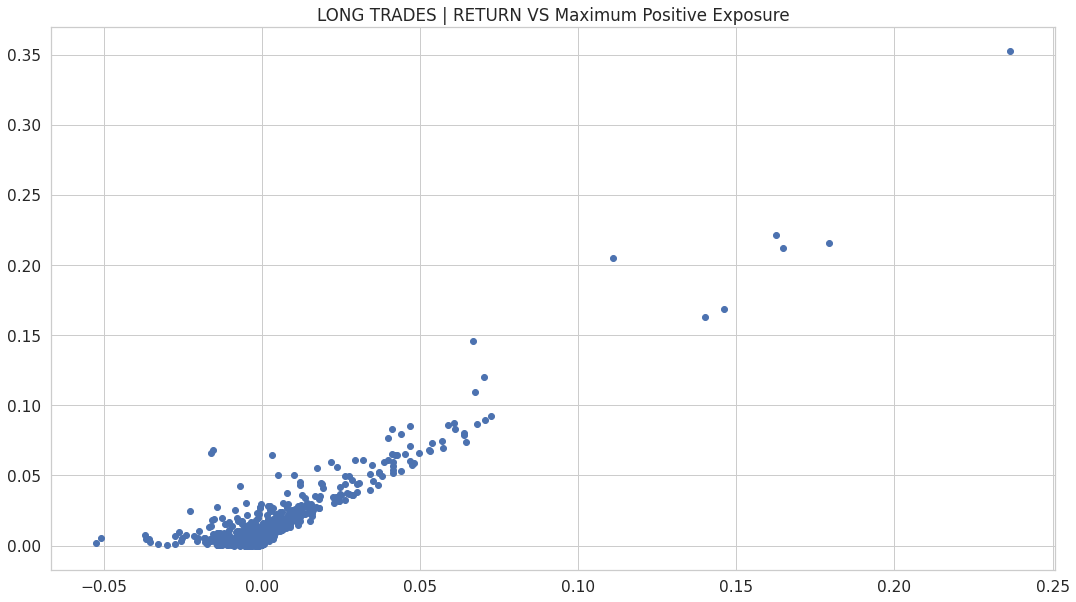

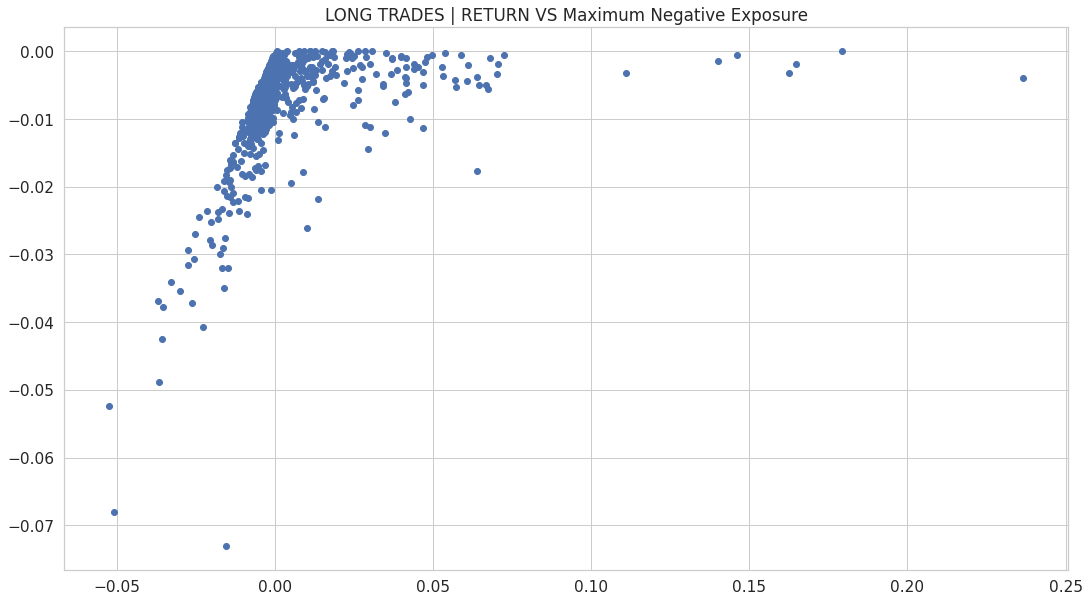

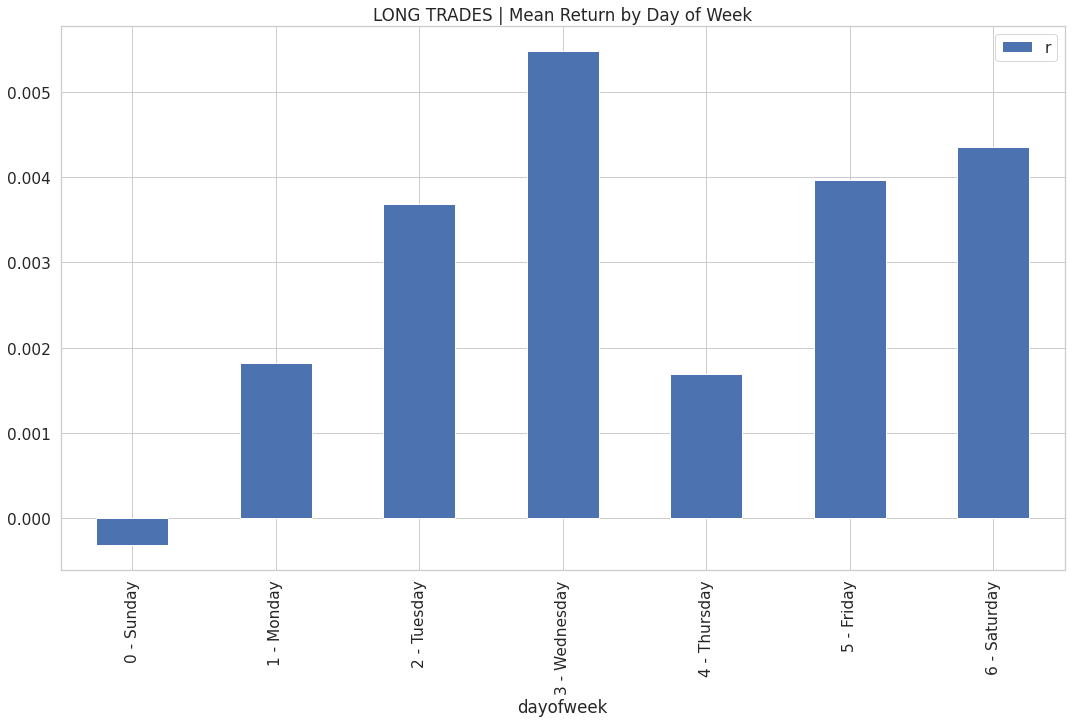

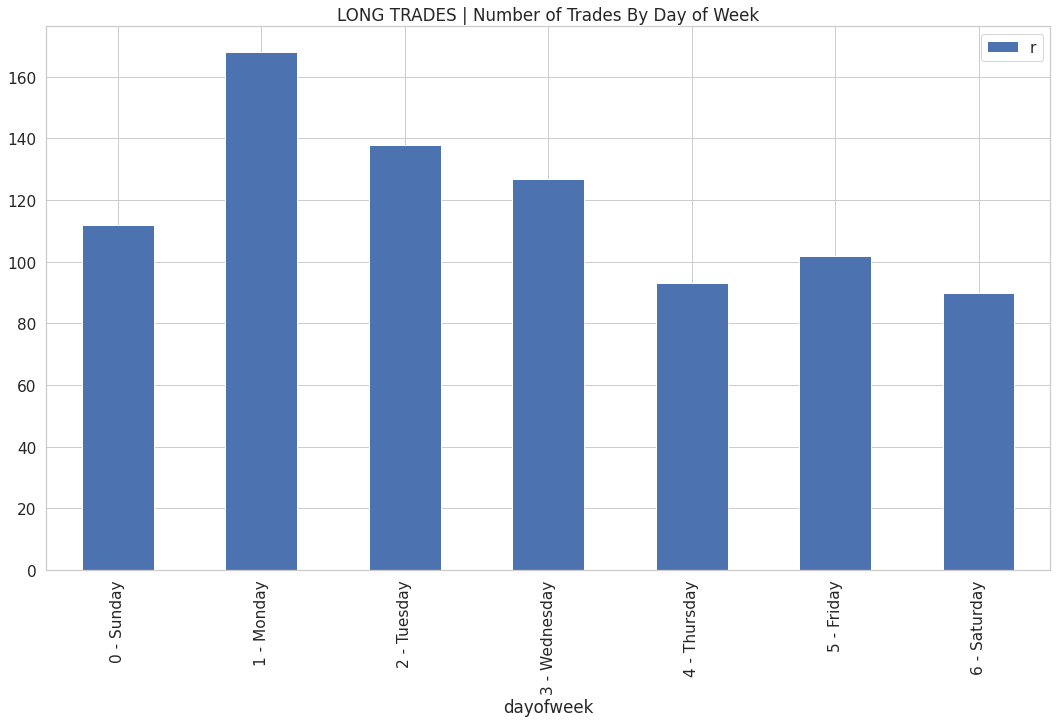

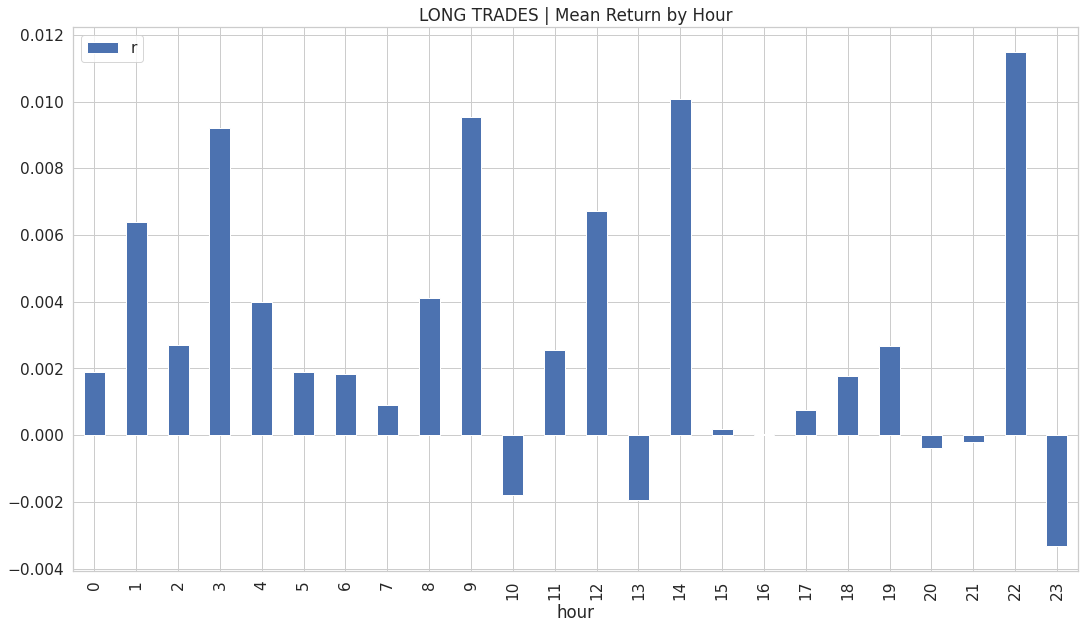

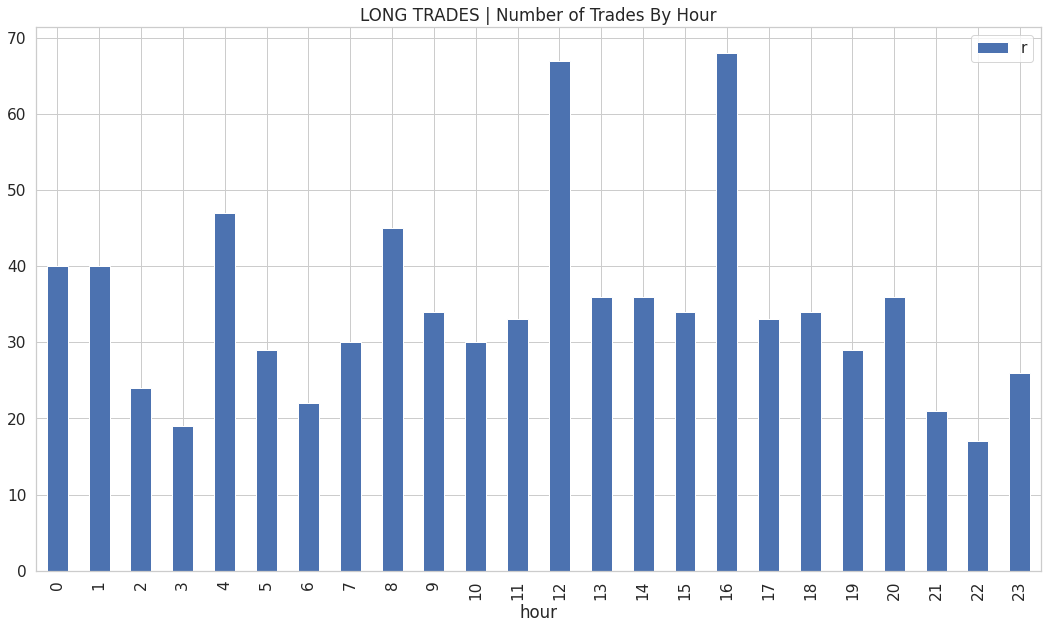




________________________________________________________________________________________________________________________________________________________________________________________________________
SHORT TRADES


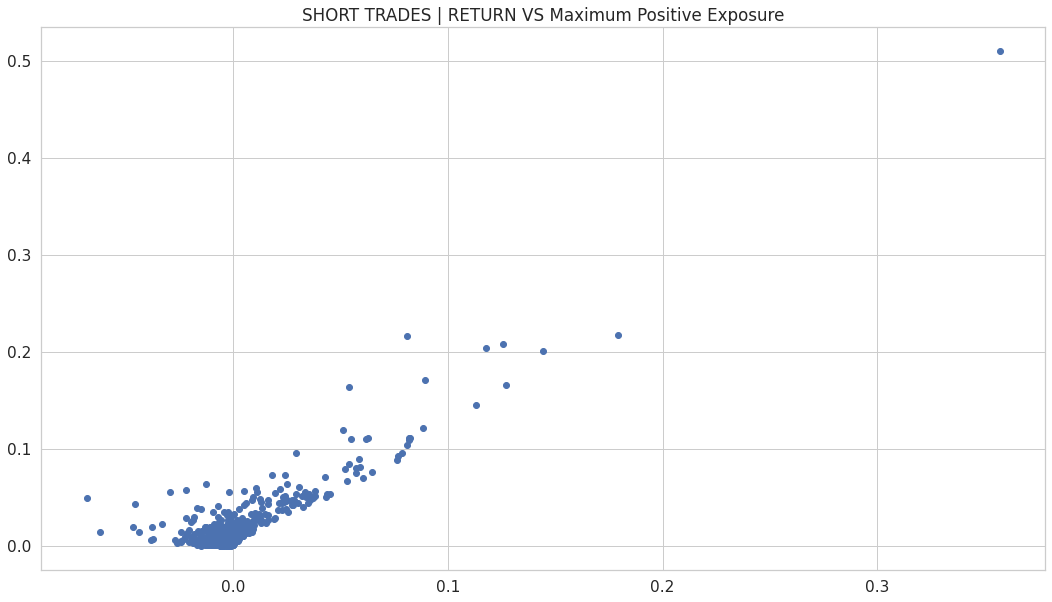

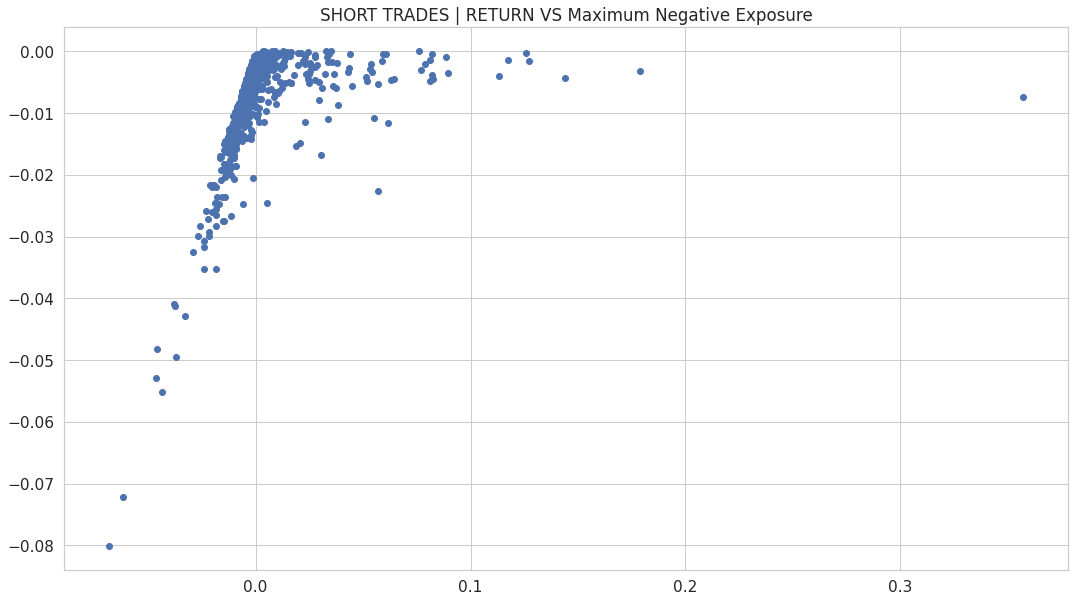

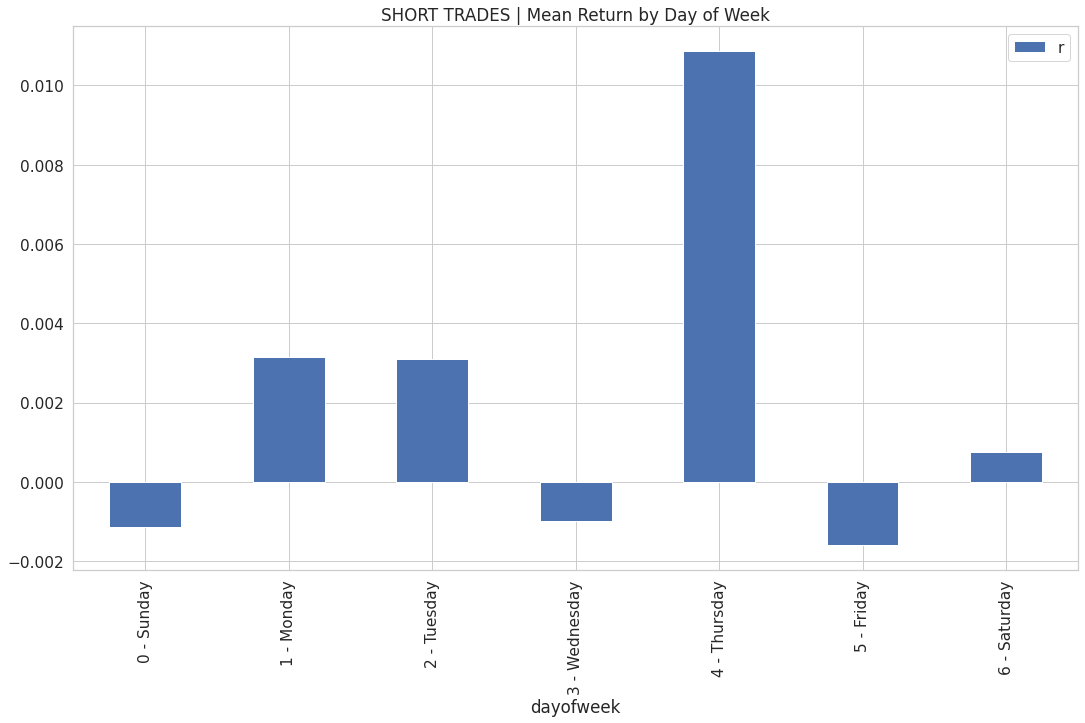

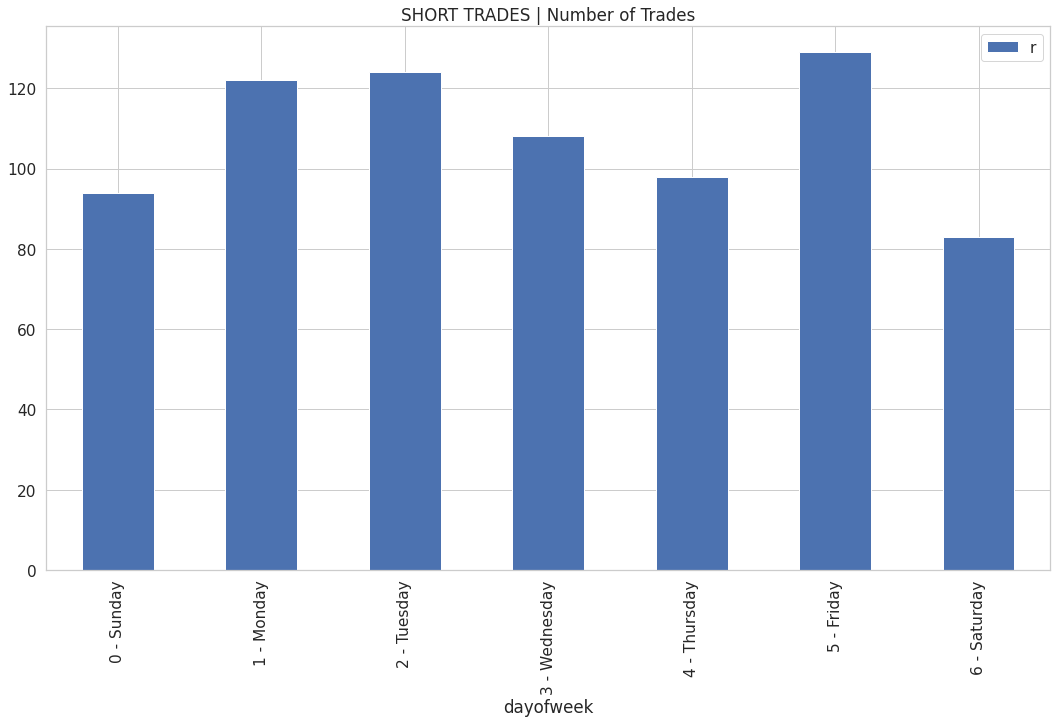

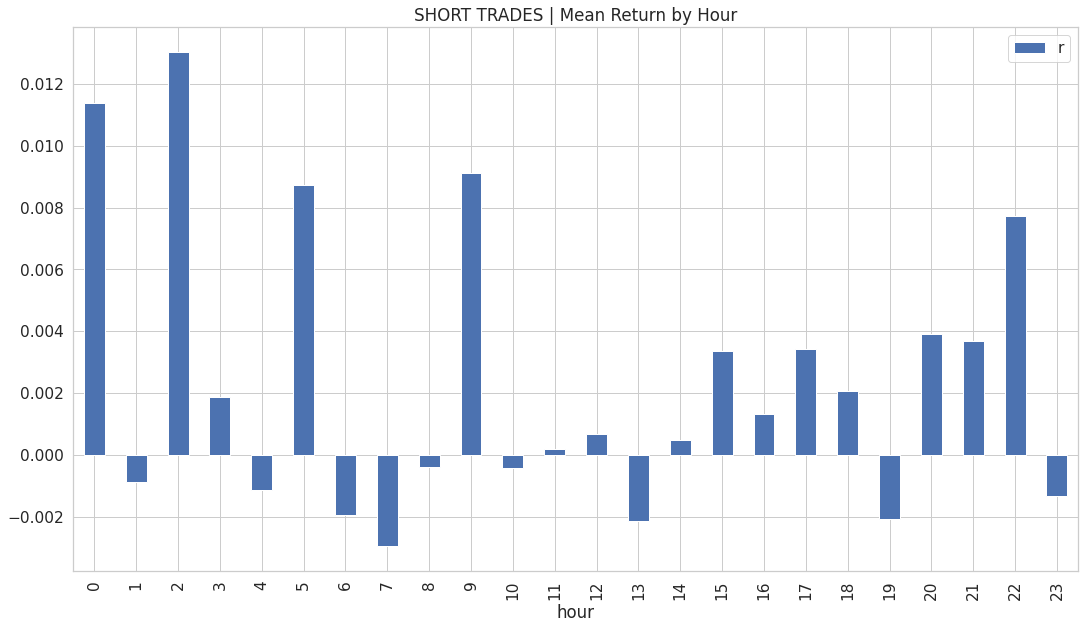

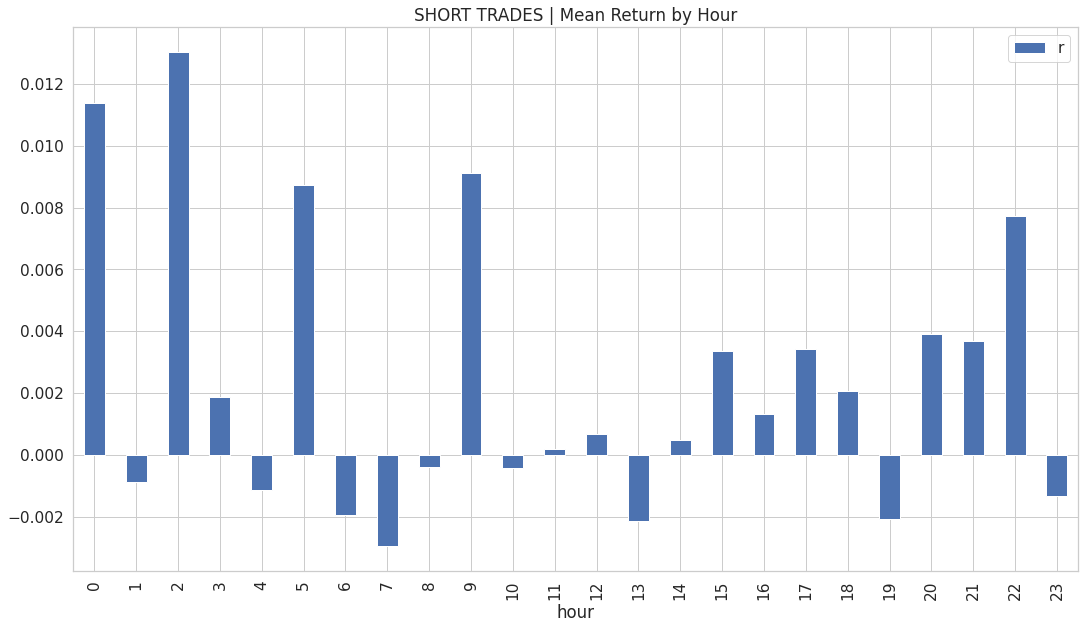

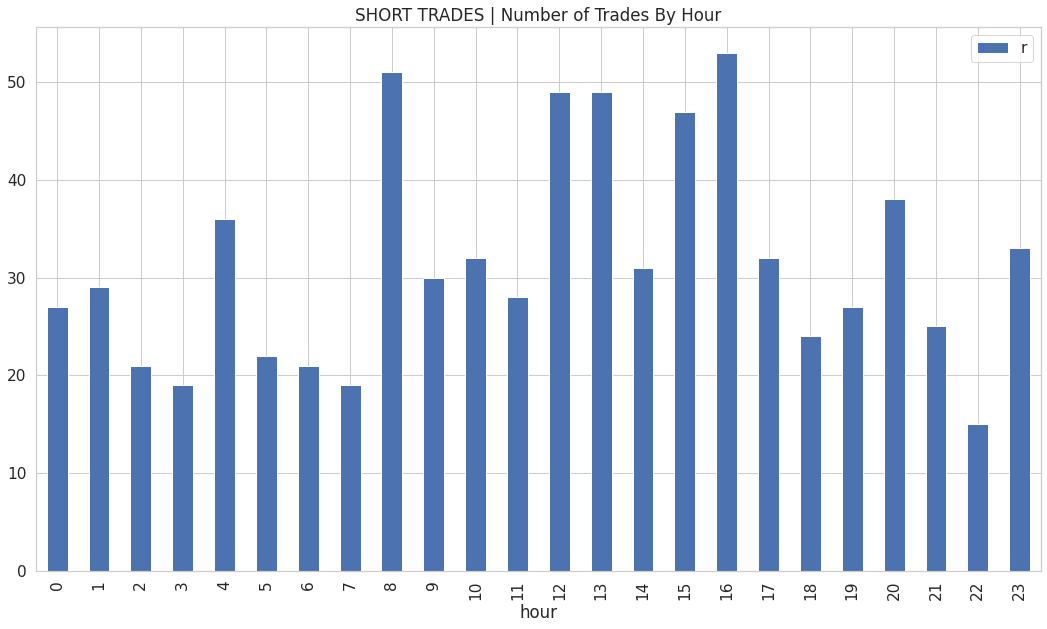

In [37]:
btc_model.plot_equity()
btc_model.plot_insights()

## **5.2 - Ethereum Model Example**

For this example we have two models that will work together, the first was optimized for higher *LONG* PNL and the second was optimized for *SHORT* PNL.

So it will be showed the models individually first, after that we will see them together. 

**NOTE:** *'BOTH SIDES'* part means that the model will long and short, while the bellow visualization will show it 'LONG ONLY' or 'SHORT ONLY'

### **5.2.1 - LONG OPTIMIZED MODEL**

#### **BOTH SIDES**

PNL: 5940958.38 | LONG: 7525805.030000002 | SHORT: -1858272.9499999979


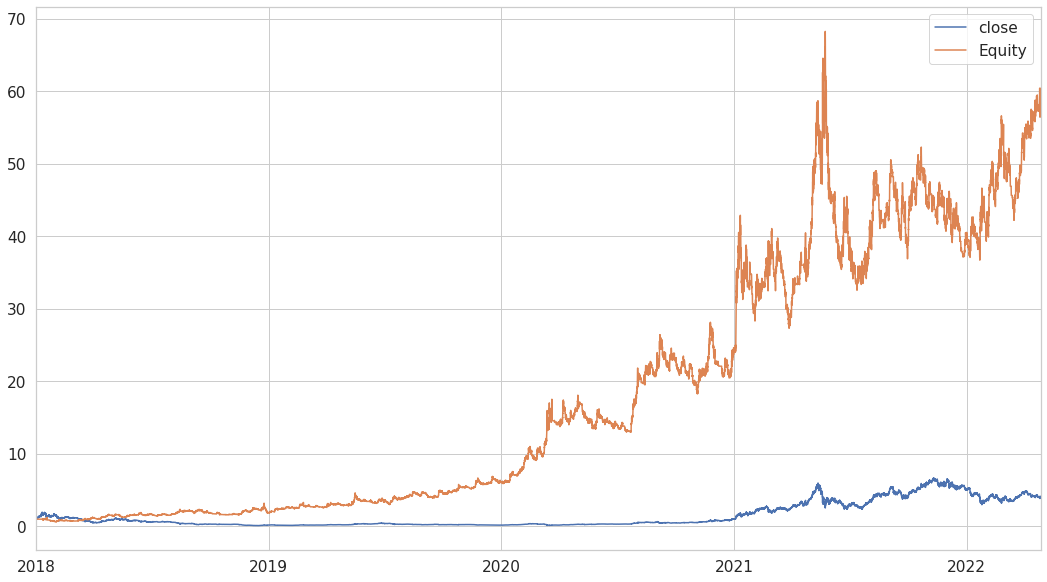

In [39]:
eth_long = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH LONG'], 
                       short_params=models_params['ETH LONG'], 
                       target_coin='ETH',
                       trade_side=0)

eth_long.backtest_run()
eth_long.plot_equity()

#### **LONG ONLY**

PNL: 3893395.53 | LONG: 3893395.5299999975 | SHORT: 0.0


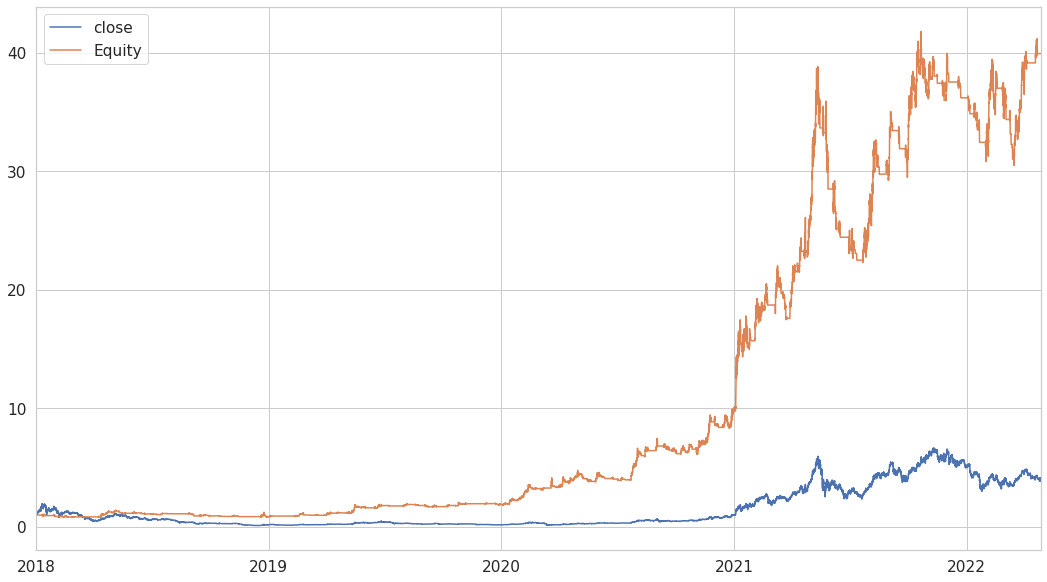

In [40]:
eth_long_only = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH LONG'], 
                       short_params=models_params['ETH LONG'], 
                       target_coin='ETH',
                       trade_side=1)

eth_long_only.backtest_run()
eth_long_only.plot_equity()

### **5.2.2 - SHORT OPTIMIZED MODEL**

#### **BOTH SIDES**

PNL: 7080142.73 | LONG: 2214733.0000000033 | SHORT: 4741837.700000003


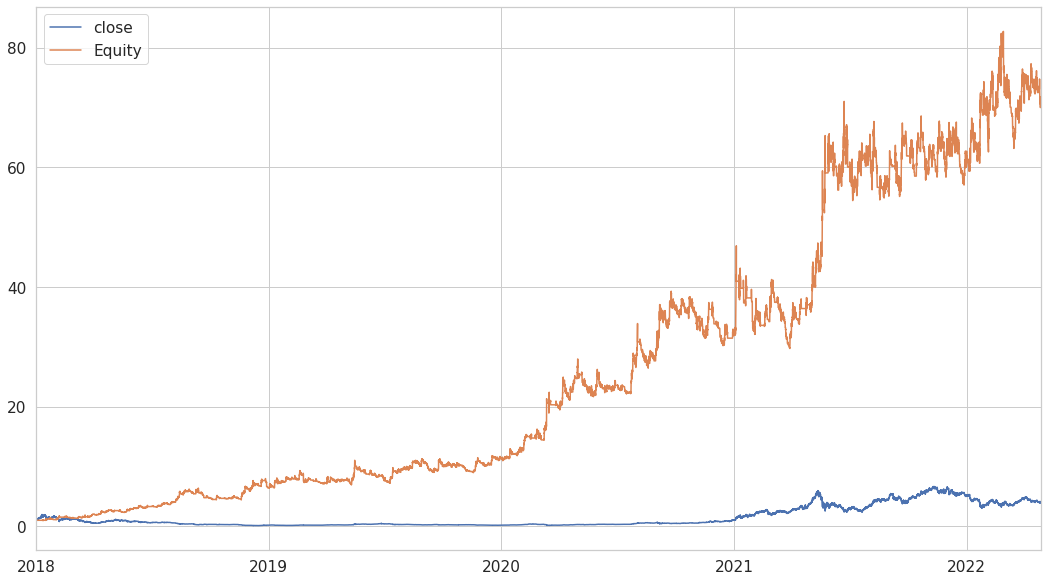

In [43]:
eth_short = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH SHORT'], 
                       short_params=models_params['ETH SHORT'], 
                       target_coin='ETH',
                       trade_side=0)

eth_short.backtest_run()
eth_short.plot_equity()

#### **SHORT ONLY**

PNL: 1587990.78 | LONG: 0.0 | SHORT: 1558938.5800000008


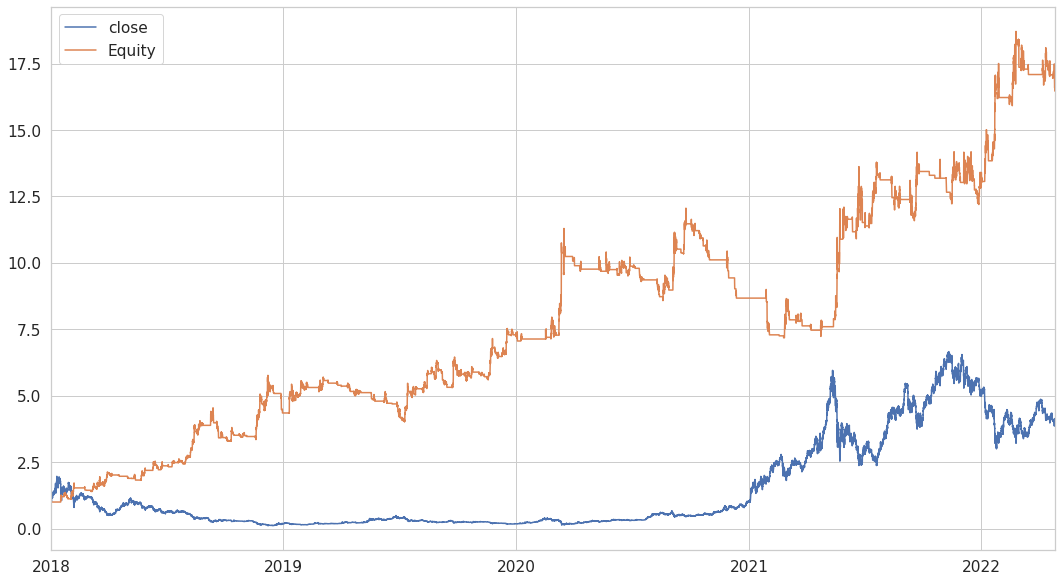

In [44]:
eth_short_only = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH SHORT'], 
                       short_params=models_params['ETH SHORT'], 
                       target_coin='ETH',
                       trade_side=-1)

eth_short_only.backtest_run()
eth_short_only.plot_equity()

### **5.2.3 - MERGED ETHEREUM MODEL**

**Comments on the models:**

The models optimized for Long or Short, both looks good and workable. But some points must be highlighted:
- **LONG MODEL**
  - Have some potential, but it is highly unstable
  - Can become a good model with some adjustments on the trade side ( stop loss for example )
- **SHORT MODEL**
  - It looks far more stable, and to be workable it looks like it needs few fixes

Both are not bad models, but maybe they can work better together.

PNL: 63164604.55 | LONG: 36682244.9 | SHORT: 25393352.959999986


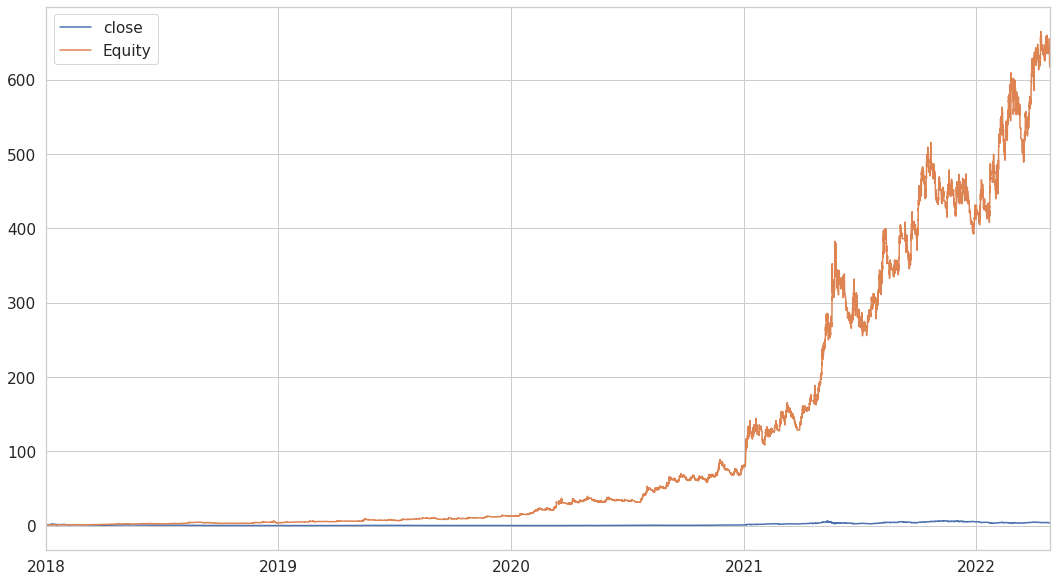

In [45]:
eth_model = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH LONG'], 
                       short_params=models_params['ETH SHORT'], 
                       target_coin='ETH',
                       trade_side=0)

eth_model.backtest_run()
eth_model.plot_equity()

________________________________________________________________________________________________________________________________________________________________________________________________________
LONG TRADES


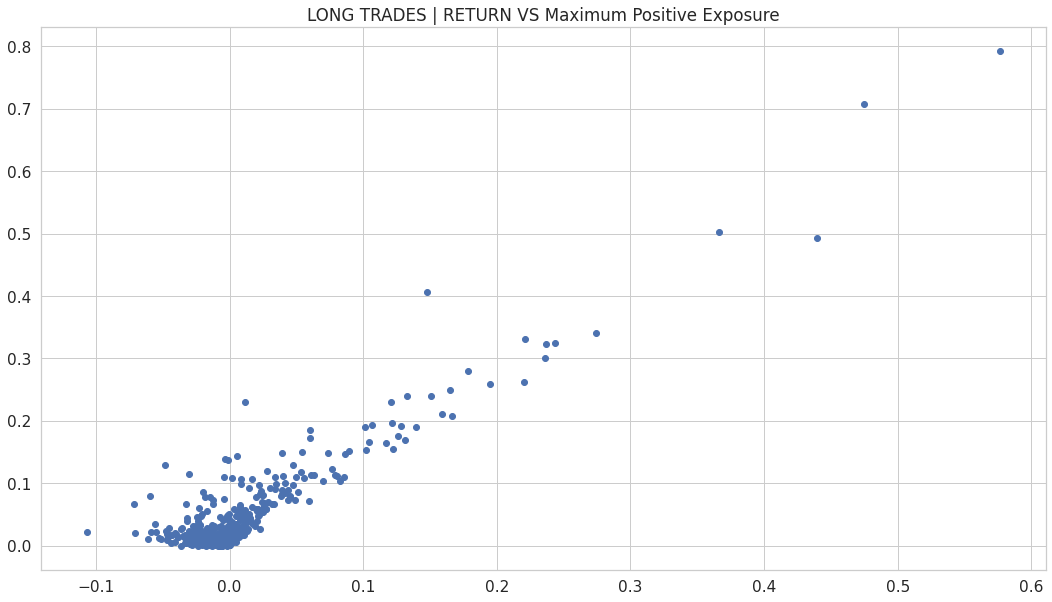

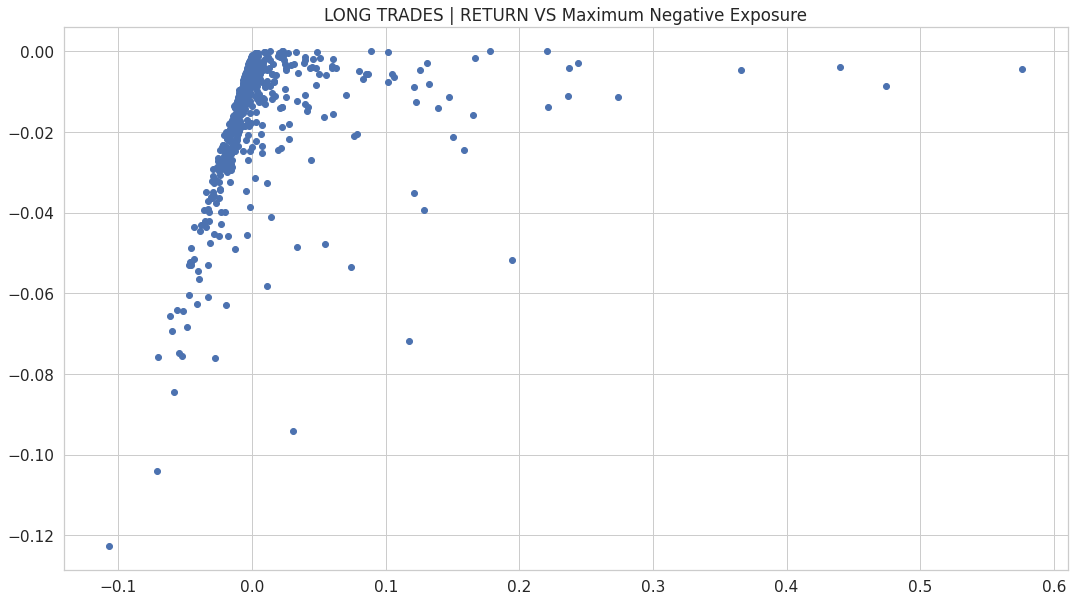

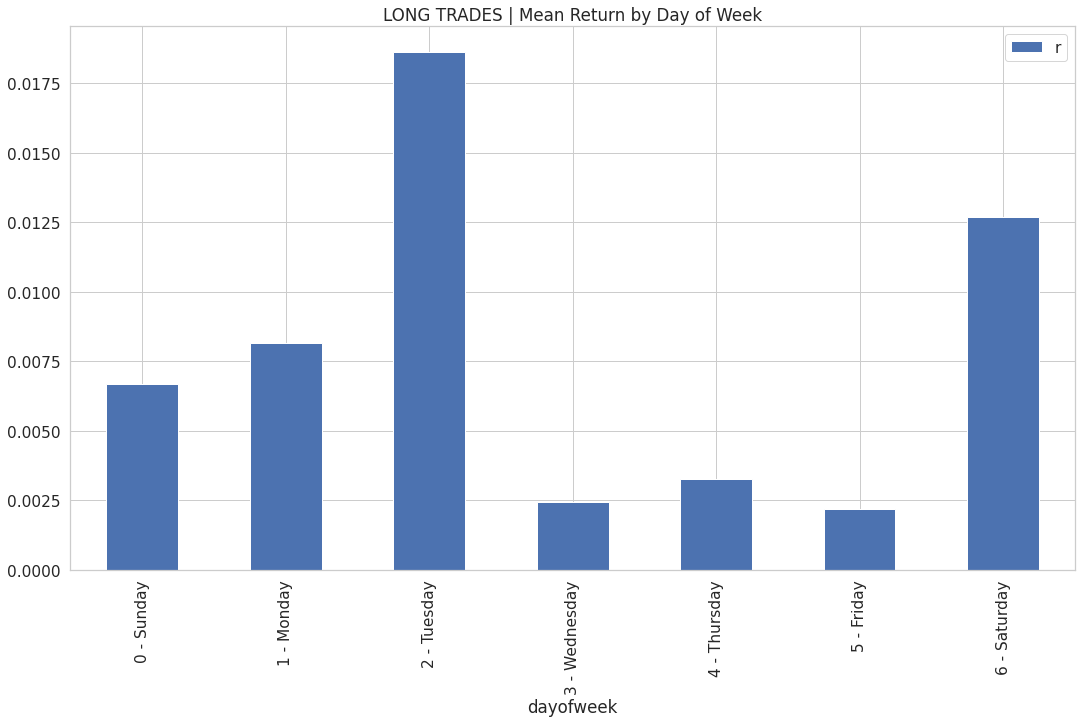

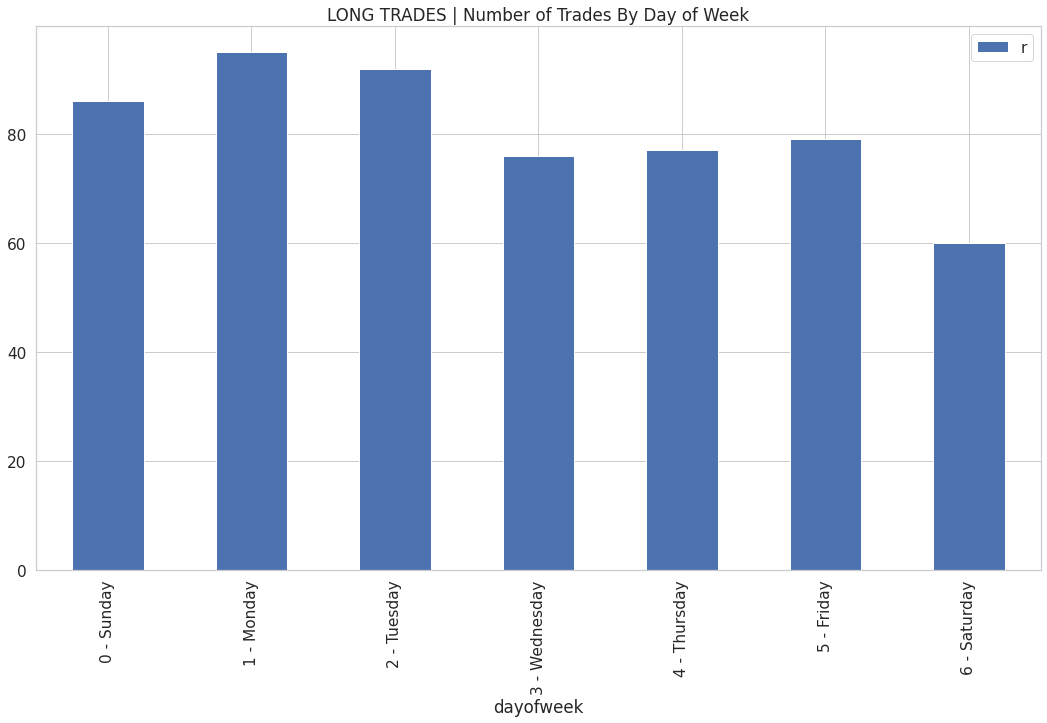

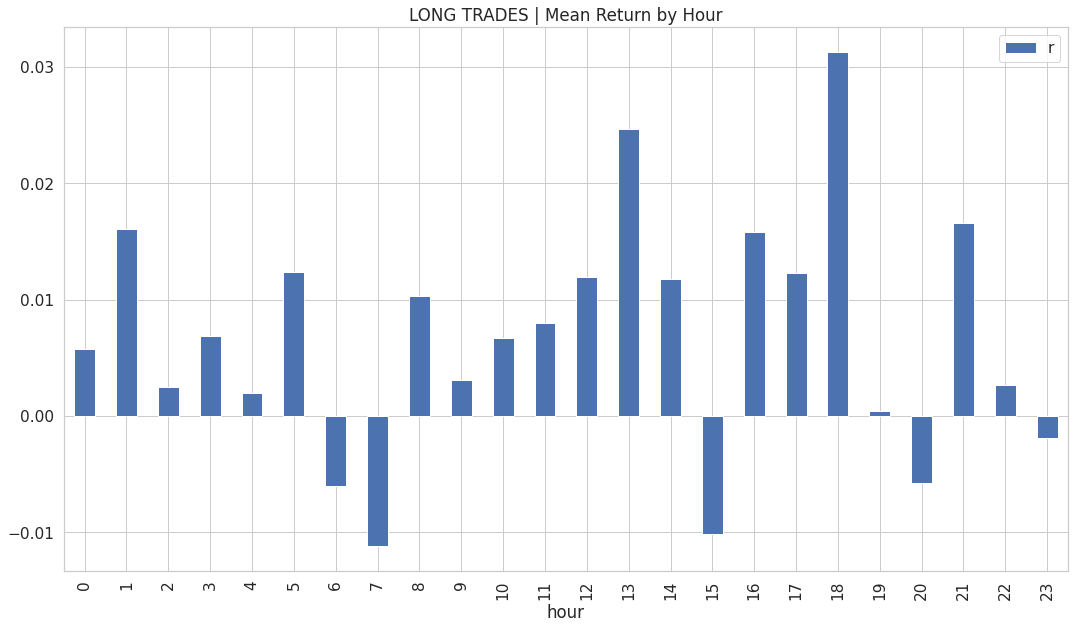

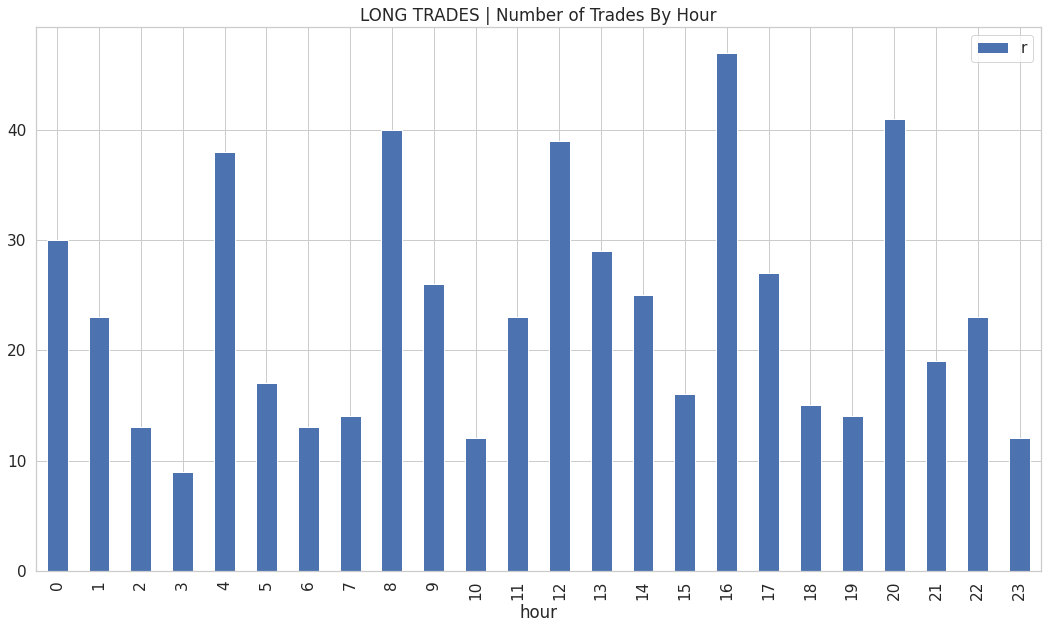




________________________________________________________________________________________________________________________________________________________________________________________________________
SHORT TRADES


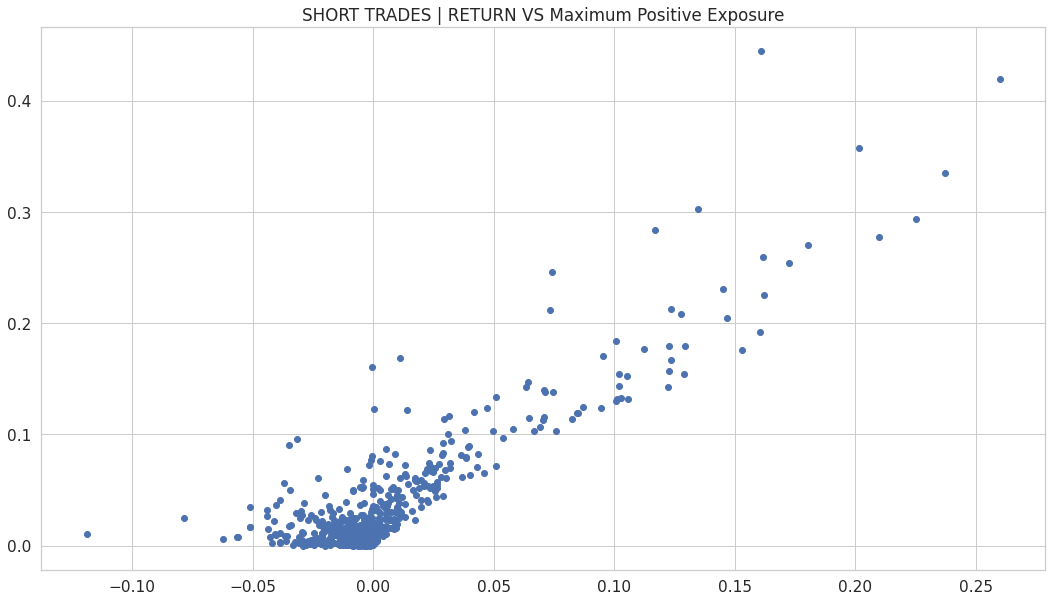

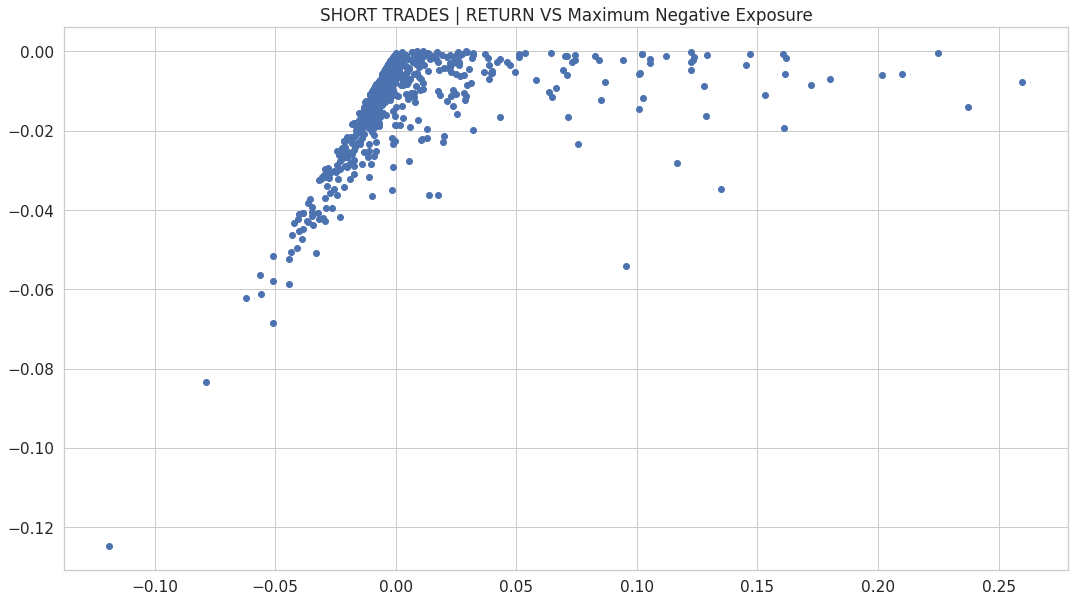

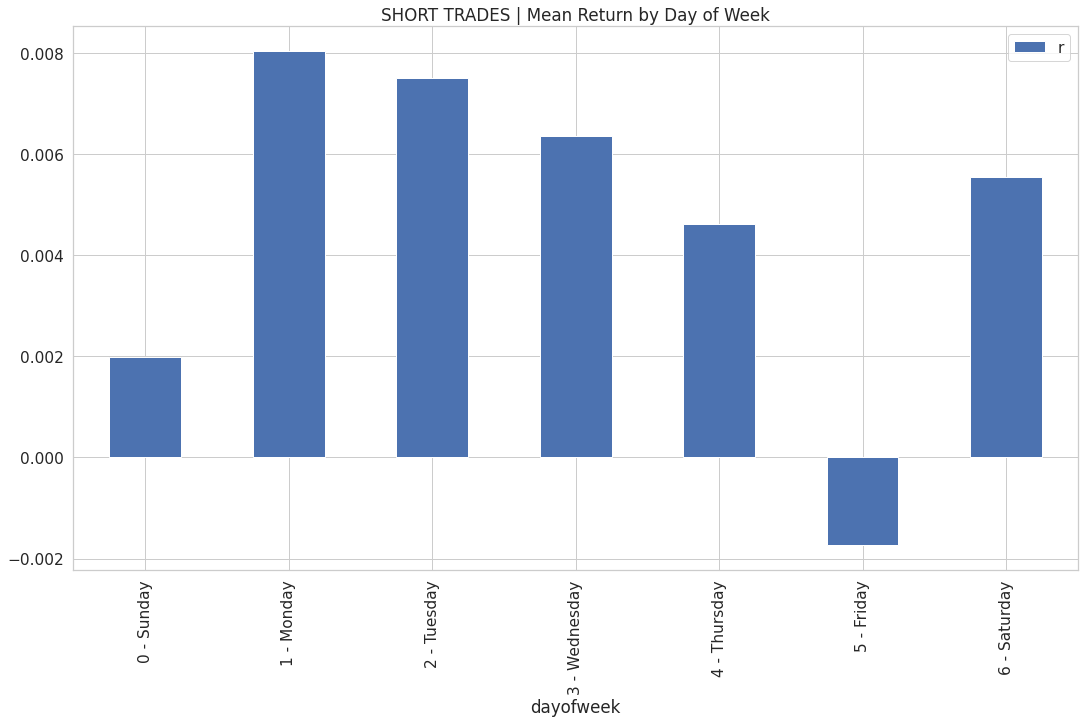

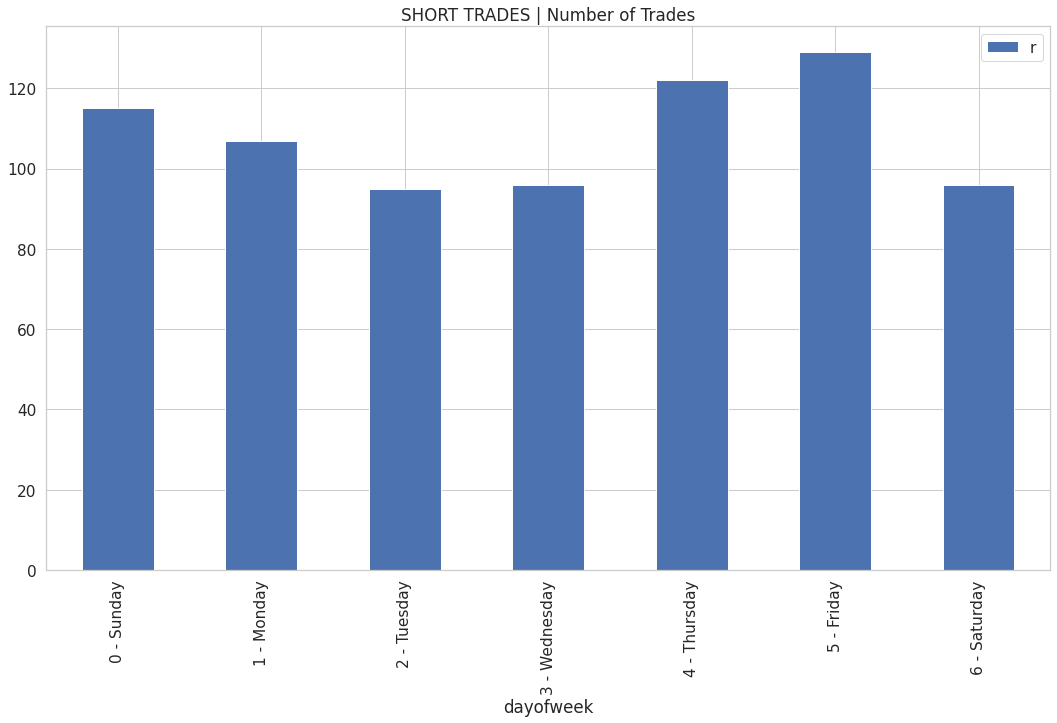

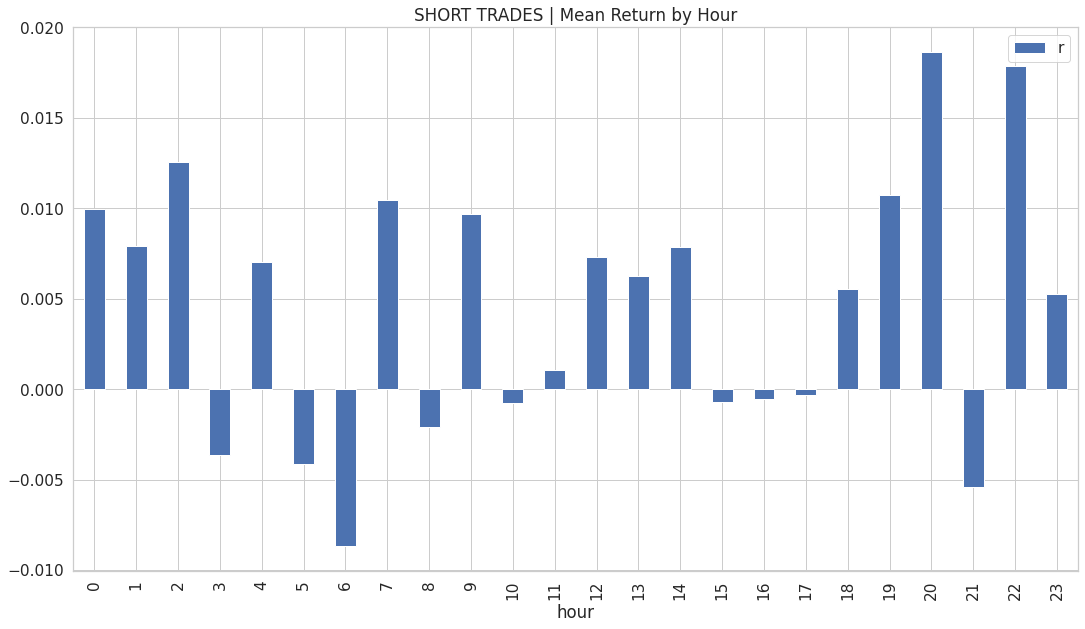

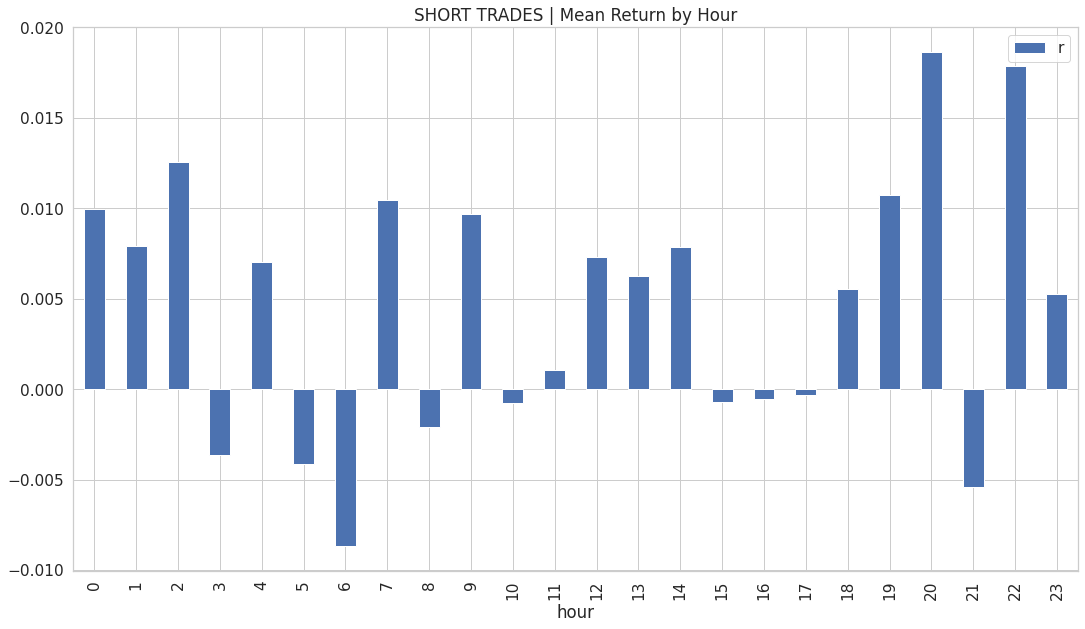

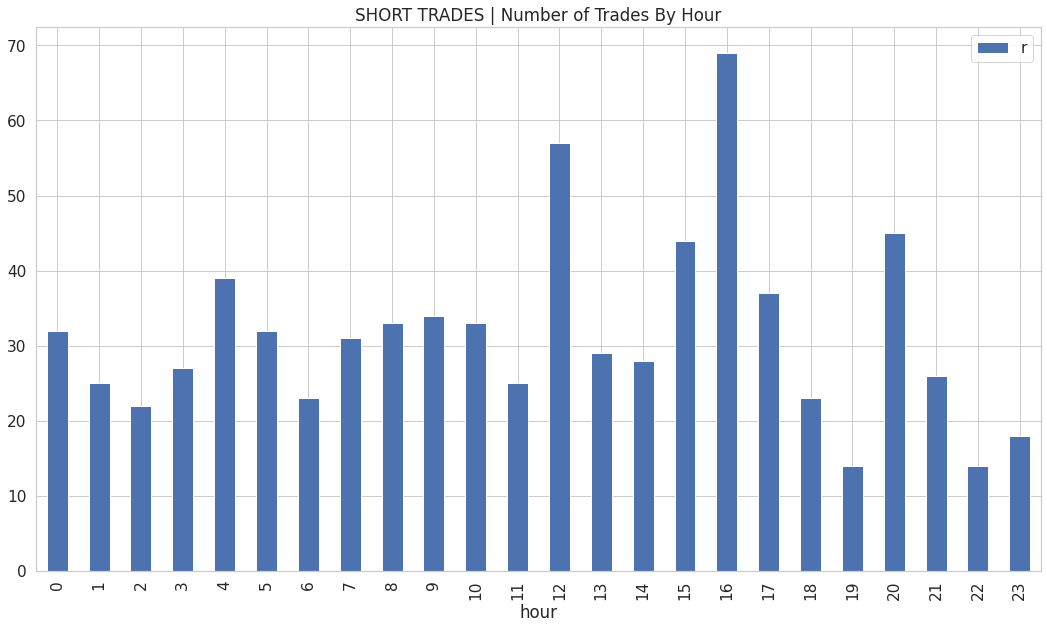

In [47]:
eth_model.plot_insights()

# **6 - Signal Transfer**

 <h1><center><strong>6 - Signal Transfer</strong></center></h1> <a name="Part6"></a>

  <center>
 
 [Go back to INDEX](#Part0)
 
 </center>

 
 ---

## **6.1 - Showcase - SOLANA | BTC & ETH Models**
***Using BTC and ETH Models***

Note: Not the signals, but the same parameters for calc.

**SOLANA - USING BITCOIN MODEL**

PNL: 94646.63 | LONG: 55055.55389999994 | SHORT: 39591.07670000002


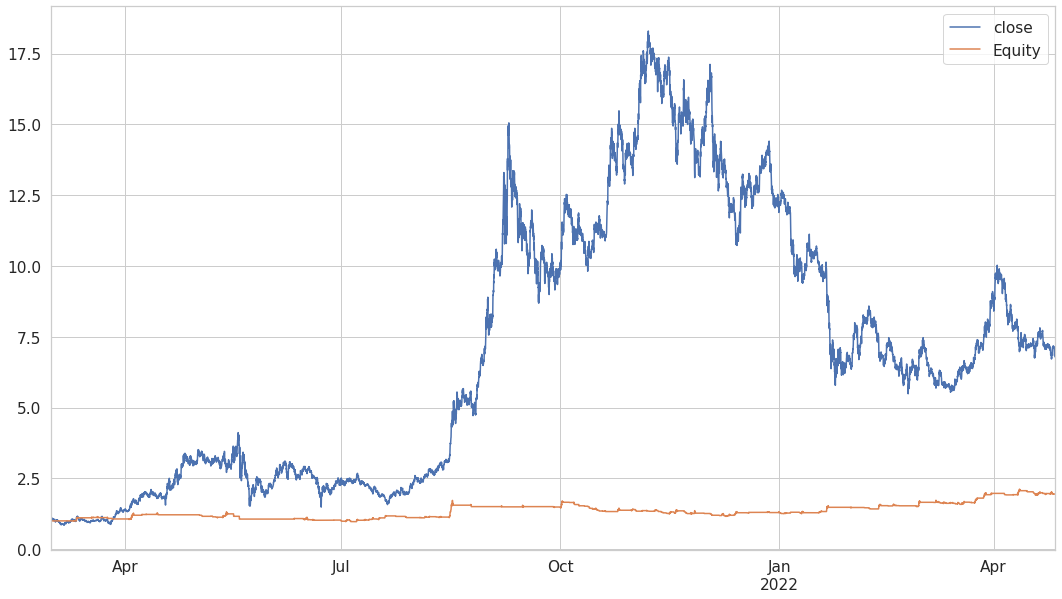

In [51]:
sol_signal_btc_model = ObvModels(model_coin='SOL', 
                       long_params=models_params['BTC MODEL'], 
                       short_params=models_params['BTC MODEL'], 
                       target_coin='SOL',
                       btc_m_beta= False,
                       btc_m_beta_side=-1,
                       btc_t_beta=False,
                       btc_t_beta_side=-1, 
                       m_t_beta=False, 
                       m_t_beta_side=-1,
                       trade_side=0)
#obv_signal.run_html('SOL_signals')
sol_signal_btc_model.backtest_run()
sol_signal_btc_model.plot_equity()

**SOLANA - USING ETHEREUM MODEL**

PNL: 92153.77 | LONG: 110731.0384999999 | SHORT: -20214.860600000353


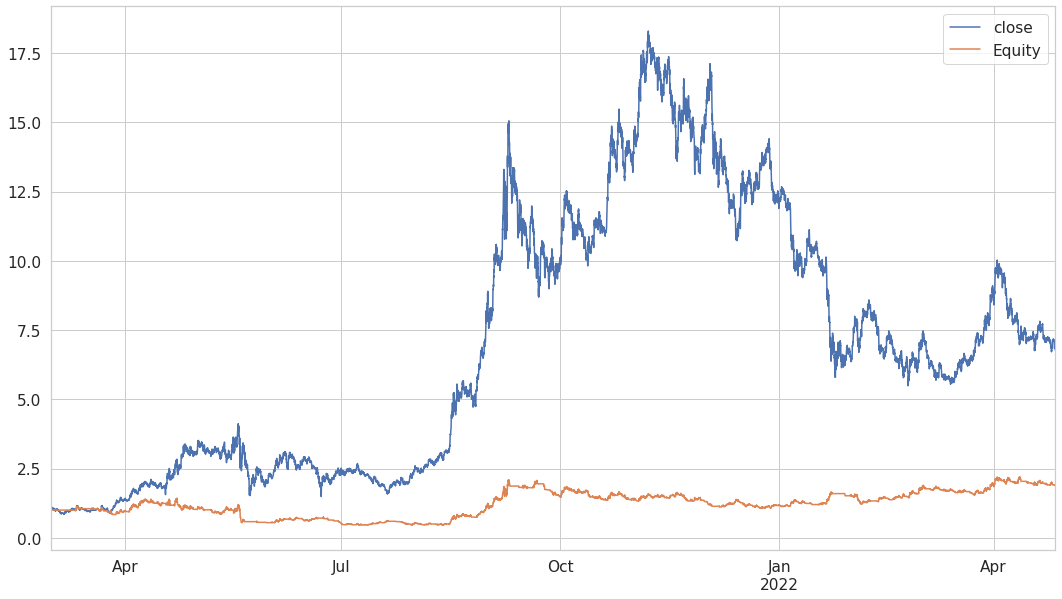

In [49]:
sol_signal_eth_model = ObvModels(model_coin='SOL', 
                       long_params=models_params['ETH LONG'], 
                       short_params=models_params['ETH SHORT'], 
                       target_coin='SOL',
                       btc_m_beta= False,
                       btc_m_beta_side=-1,
                       btc_t_beta=False,
                       btc_t_beta_side=-1, 
                       m_t_beta=False, 
                       m_t_beta_side=-1,
                       trade_side=0)
#obv_signal.run_html('SOL_signals')
sol_signal_eth_model.backtest_run()
sol_signal_eth_model.plot_equity()

## **6.2 - Showcase - SOLANA | BTC & ETH SIGNALS**

**SOLANA - USING BITCOIN SIGNAL**

PNL: -35237.82 | LONG: 36068.03050000005 | SHORT: -71305.85469999987


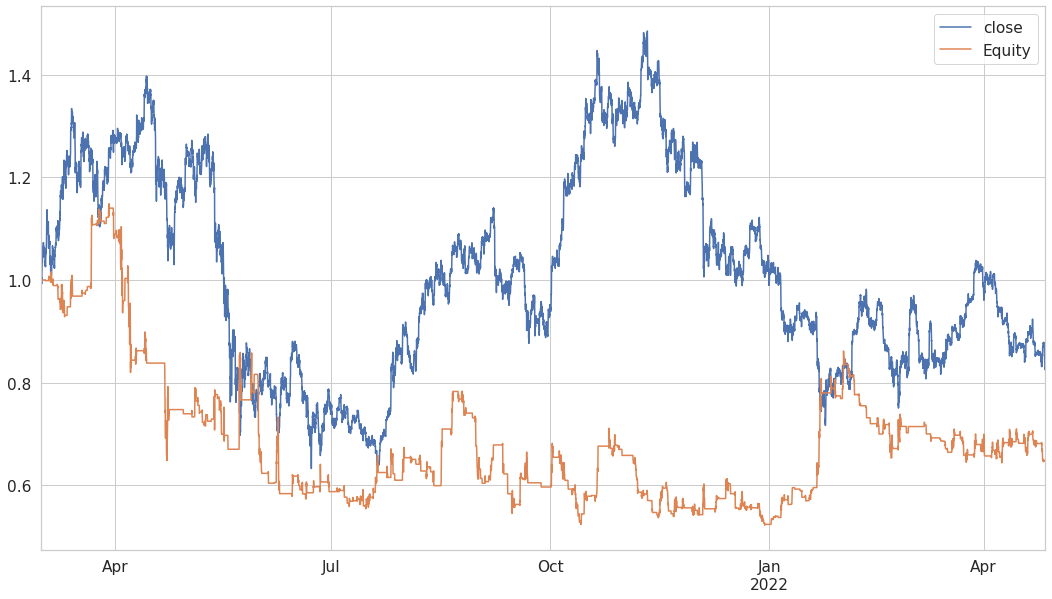

In [52]:
sol_signal_btc_signal = ObvModels(model_coin='BTC', 
                       long_params=models_params['BTC MODEL'], 
                       short_params=models_params['BTC MODEL'], 
                       target_coin='SOL',
                       btc_m_beta= False,
                       btc_m_beta_side=-1,
                       btc_t_beta=False,
                       btc_t_beta_side=-1, 
                       m_t_beta=False, 
                       m_t_beta_side=-1,
                       trade_side=0)
#obv_signal.run_html('SOL_signals')
sol_signal_btc_signal.backtest_run()
sol_signal_btc_signal.plot_equity()

**SOLANA - USING ETHEREUM SIGNAL**

PNL: 312044.91 | LONG: 185723.0241000001 | SHORT: 122809.32410000009


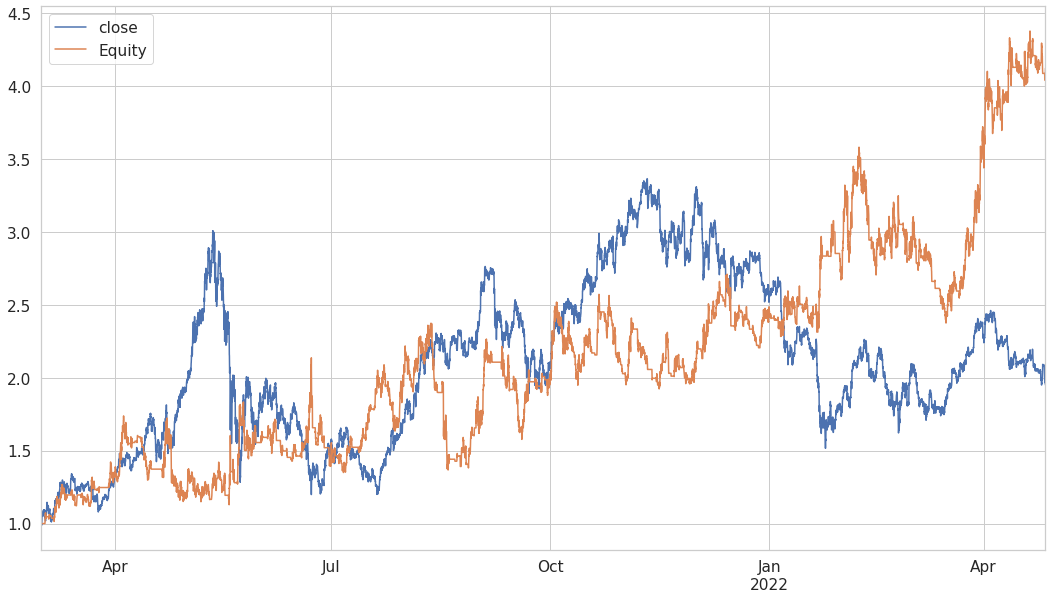

In [53]:
sol_signal_eth_signal = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH LONG'], 
                       short_params=models_params['ETH SHORT'], 
                       target_coin='SOL',
                       btc_m_beta= False,
                       btc_m_beta_side=-1,
                       btc_t_beta=False,
                       btc_t_beta_side=-1, 
                       m_t_beta=False, 
                       m_t_beta_side=-1,
                       trade_side=0)
#obv_signal.run_html('SOL_signals')
sol_signal_eth_signal.backtest_run()
sol_signal_eth_signal.plot_equity()

## **6.3 - Showcase - SOLANA | BTC & ETH SIGNALS | BETA FILTER**

We can see from tests that signal transfer can generate some sort of return, especially when we look at Solana replicating Ethereum signals.

Despite being good, the difference between replicating BTC and ETH signals implied that the coin has some significant correlation with Ethereum, so it is possible to think that the filter using Beta (Covariance) can improve how the target coin takes advantage of these signals.

First of all, I believe it is important to explain what these new variables are in the initialization of the class.

- **btc_m_beta**: Beta between model base coin and bitcoin ( default=False ) 
- **btc_t_beta**: Beta between target(eg.Solana) coin and bitcoin ( default=False ) 
- **m_t_beta**: Beta between target coin and model base coin ( default=False ) 

The other variables that have the exact name plus '_side' means that:
- **1:** beta > threshold
- **-1:** beta < threshold

These values are used as thresholds to start or end a trade.

**BITCOIN SIGNAL TEST**

Because it is a signal coming from Bitcoin, the only beta that you can choose is the Beta between the target coin and Bitcoin.

I will not explore too much the bitcoin signal, since it seems that they have low correlation ( at least to transfer signals )

**Beta < 1**

PNL: 53710.46 | LONG: 67890.83720000011 | SHORT: -14180.38199999999


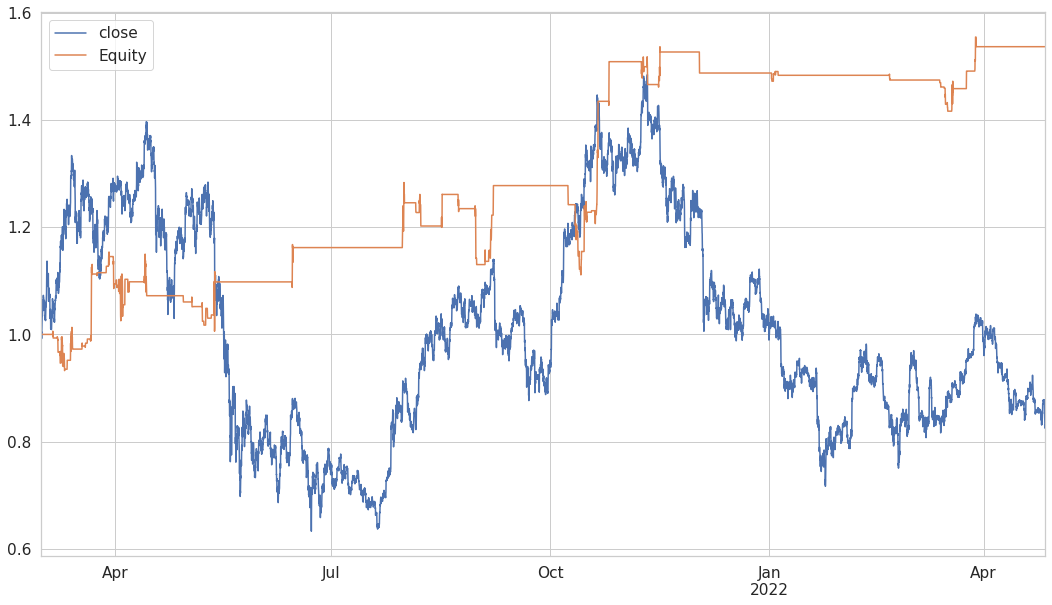

In [57]:
sol_btc_signal_beta = ObvModels(model_coin='BTC', 
                       long_params=models_params['BTC MODEL'], 
                       short_params=models_params['BTC MODEL'], 
                       target_coin='SOL',
                       btc_t_beta=1,
                       btc_t_beta_side=-1, 
                       trade_side=0)
#obv_signal.run_html('SOL_signals')
sol_btc_signal_beta.backtest_run()
sol_btc_signal_beta.plot_equity()

**BETA > 1**

PNL: -54167.5 | LONG: -1284.3588000000173 | SHORT: -52883.139599999835


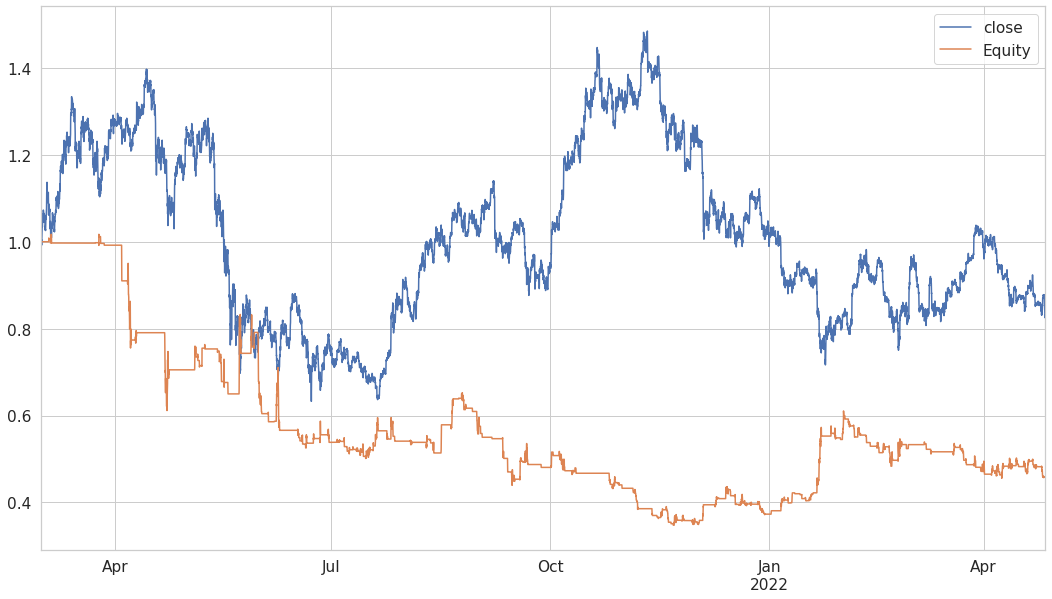

In [58]:
sol_btc_signal_beta = ObvModels(model_coin='BTC', 
                       long_params=models_params['BTC MODEL'], 
                       short_params=models_params['BTC MODEL'], 
                       target_coin='SOL',
                       btc_t_beta=1,
                       btc_t_beta_side=1, 
                       trade_side=0)
#obv_signal.run_html('SOL_signals')
sol_btc_signal_beta.backtest_run()
sol_btc_signal_beta.plot_equity()

**ETHEREUM SIGNAL TEST**

Ethereum looks like it can "drag" SOLANA.

So following the findings with the Bitcoin signal -> Solana we could notice that lower betas can benefit the model.

Since Ethereum and Altcoins usually have higher Betas, I will make a test with higher betas thresholds, but as `beta < threshold`

**ETH x BTC Beta < 1.5**

**SOLANA x BTC Beta < 1.4**

The idea behind it is simple:

- Ethereum seems to drag Solana, but we want a movement where ETH start a movement with low correlation to BTC.
- Since the altcoin is following ETH, we want it to have low correlation ( covariance ) with BTC.

PNL: 576552.85 | LONG: 172076.10009999984 | SHORT: 398709.9071999999


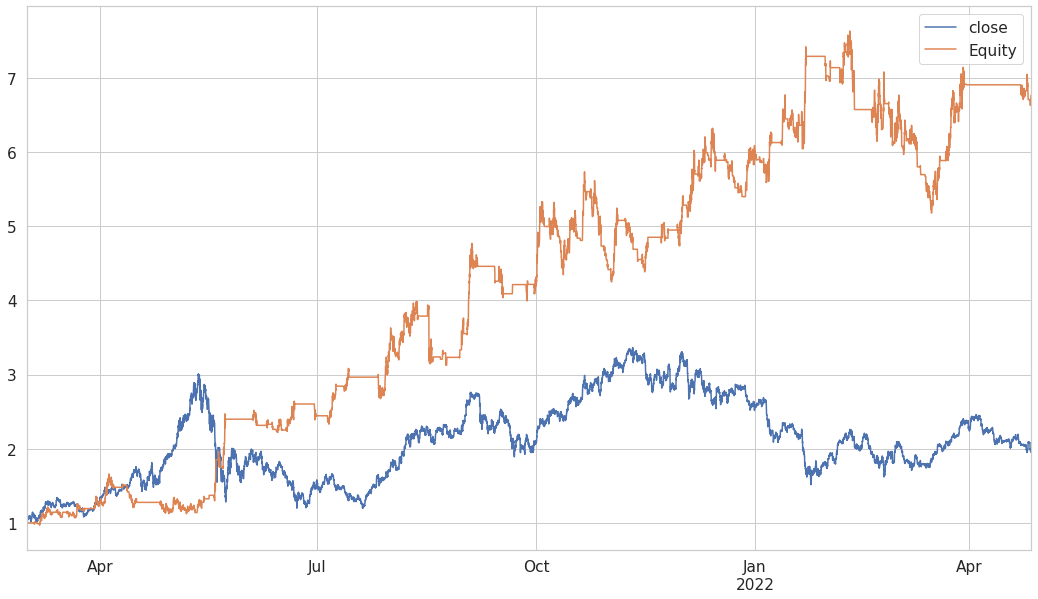

In [59]:
sol_eth_signal_beta = ObvModels(model_coin='ETH', 
                       long_params=models_params['ETH LONG'], 
                       short_params=models_params['ETH SHORT'], 
                       target_coin='SOL',
                       btc_m_beta= 1.5,
                       btc_m_beta_side=-1,
                       btc_t_beta=1.4,
                       btc_t_beta_side=-1, 
                       m_t_beta=False, 
                       m_t_beta_side=-1,
                       trade_side=0)

#obv_signal.run_html('SOL_signals')
sol_eth_signal_beta.backtest_run()
sol_eth_signal_beta.plot_equity()

# **7 - Comments and Suggestions**

 <h1><center><strong>Comments and Suggestions</strong></center></h1> <a name="Part7"></a>

  <center>
 
 [Go back to INDEX](#Part0)
 
 </center>

 
 ---